# Exploratory Data Analysis

Inspect the full `merged_order_items` table from `data/interim`. One row represents an order item, identified by `(order_id, order_item_id)`.

The workflow covers structure, distributions, missingness, domain checks and detailed inspection of unusual records. All observations retain their original values and statuses. Diagnostic tables and figures remain in memory; this notebook writes no datasets or documentation.

Run all cells in order. Section functions in `src.eda.workflow` display their evidence and return complete result objects for further inspection. Cleaning, feature engineering and delivery-performance analysis are separate workflows.


## 1. Input and execution context

### Repository location

Locate the repository from the current working directory before importing project modules. Execution is supported from the repository root or its `notebooks` directory.


In [15]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display


# Locate the repository before importing project modules.
def find_project_root(start_path: Path) -> Path:
    """Find the project root containing src/ and requirements.txt."""
    for path in [start_path, *start_path.parents]:
        if (path / "src").is_dir() and (path / "requirements.txt").is_file():
            return path

    raise FileNotFoundError(
        "Could not locate project root containing both 'src/' and 'requirements.txt'."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


In [16]:
from src.data_loader import load_data
from src.eda.checks import build_entity_views, profile_entity_consistency, profile_keys
from src.eda.profiling import get_column_roles, profile_columns, profile_dataset
from src.eda.workflow import (
    inspect_numeric_distributions,
    inspect_category_distributions,
    inspect_temporal_distributions,
    inspect_missing_patterns,
    inspect_missing_pairs,
    inspect_conditional_missingness,
    inspect_status_missingness,
    inspect_text_formats,
    inspect_order_timeline,
    inspect_measurement_plausibility,
    inspect_order_structure,
    inspect_timeline_details,
    inspect_delivered_completeness,
    inspect_product_completeness,
    inspect_numeric_tails,
    inspect_deadline_calendar,
    inspect_seller_city_spacing,
    inspect_structure_overlap,
)
from src.paths import INTERIM_DIR
from src.pipeline.contracts.schema import BENCHMARK_ROW_COUNT, FULL_MERGE_SCHEMA

print(f"Project root: {PROJECT_ROOT}")
print(f"Interim data path: {INTERIM_DIR}")


Project root: /Users/nguyenvietnhat/Documents/GitHub/Intro-to-DataScience-Project
Interim data path: /Users/nguyenvietnhat/Documents/GitHub/Intro-to-DataScience-Project/data/interim


### Load the full merged table

The schema-aware reader tries Parquet first and falls back to CSV. Set `file_format="csv"` to read CSV directly.

The in-memory baseline records shape, column order, dtypes and indexed row hashes for the final input-preservation assertion.


In [17]:
df = load_data("merged_order_items", stage="interim")

# Record the loaded input without making a second copy of the full dataset.
input_baseline = {
    "shape": df.shape,
    "columns": df.columns.copy(),
    "dtypes": df.dtypes.copy(),
    "row_hashes": pd.util.hash_pandas_object(df, index=True).copy(),
}


Loaded PARQUET from '/Users/nguyenvietnhat/Documents/GitHub/Intro-to-DataScience-Project/data/interim/merged_order_items.parquet'.


### Reference dimensions

Compare observed dimensions with the reference full merge. Reference counts identify the input version; they are not eligibility conditions or cleaning targets.


In [18]:
baseline_summary = pd.DataFrame(
    [
        ["Item rows", BENCHMARK_ROW_COUNT, len(df)],
        ["Columns", len(FULL_MERGE_SCHEMA.columns), len(df.columns)],
        ["Unique orders", 98_666, df["order_id"].nunique()],
    ],
    columns=["Metric", "Reference", "Observed"],
)
baseline_summary["Matches reference"] = baseline_summary["Reference"].eq(
    baseline_summary["Observed"]
)
display(baseline_summary)

if not baseline_summary["Matches reference"].all():
    print("Reference counts differ. Check the input version before interpreting later profiles.")

print("Input baseline retained in memory for the final non-mutation check.")


,Metric,Reference,Observed,Matches reference
0,Item rows,112650,112650,True
1,Columns,25,25,True
2,Unique orders,98666,98666,True


Input baseline retained in memory for the final non-mutation check.


### Data preview

Display the first item rows with their original column values.


In [19]:
df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,...,customer_city,customer_state,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,...,campos dos goytacazes,RJ,cool_stuff,650.0,28.0,9.0,14.0,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,...,santa fe do sul,SP,pet_shop,30000.0,50.0,30.0,40.0,03471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,...,para de minas,MG,moveis_decoracao,3050.0,33.0,13.0,33.0,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,...,atibaia,SP,perfumaria,200.0,16.0,10.0,15.0,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,...,varzea paulista,SP,ferramentas_jardim,3750.0,35.0,40.0,30.0,87900,loanda,PR


## 2. Structure and completeness

### Dataset dimensions

Full-table statistics use item rows. Exact duplicate participants count every row in a repeated-row group; excess copies exclude the first occurrence.

The merged table contains `customer_id`, which identifies a customer record attached to a purchase. It does not contain `customer_unique_id`; customer-record counts therefore do not represent unique people.


In [20]:
dataset_profile = profile_dataset(df)
display(dataset_profile)


,metric,value,unit
0,Rows,112650,item rows
1,Columns,25,columns
2,Memory usage,43504719,bytes
3,Missing cells,5338,cells
4,Rows with missing values,4007,item rows
5,Exact duplicate participants,0,item rows
6,Exact duplicate excess copies,0,item rows
7,Observed orders,98666,distinct IDs
8,Observed customers,98666,distinct IDs
9,Observed products,32951,distinct IDs


### Column roles and completeness

Column roles come from the merge schema. Source ownership describes the contributing table and its key. Identifiers and ZIP prefixes are excluded from numeric measurements.

Missing values use `isna()`. Empty or whitespace-only strings are counted separately as blanks. Percentages use all item rows; distinct non-null counts preserve original case, whitespace and blank strings.


In [21]:
column_roles = get_column_roles()
column_profile = profile_columns(df)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    print("Registered column roles")
    display(column_roles)
    print("Completeness at item grain")
    display(column_profile)


Registered column roles


,column,role,source_table,source_key,expected_dtype
0,order_id,identifier,order_items,"(order_id, order_item_id)",string
1,order_item_id,identifier,order_items,"(order_id, order_item_id)",int64
2,product_id,identifier,order_items,"(order_id, order_item_id)",string
3,seller_id,identifier,order_items,"(order_id, order_item_id)",string
4,shipping_limit_date,timestamp,order_items,"(order_id, order_item_id)",datetime64[us]
5,price,measurement,order_items,"(order_id, order_item_id)",float64
6,freight_value,measurement,order_items,"(order_id, order_item_id)",float64
7,customer_id,identifier,orders,"(order_id,)",string
8,order_status,category,orders,"(order_id,)",string
9,order_purchase_timestamp,timestamp,orders,"(order_id,)",datetime64[us]


Completeness at item grain


,column,role,dtype,rows,non_null,missing,missing_pct,blank,blank_pct,distinct_non_null
0,order_id,identifier,string,112650,112650,0,0.000000,0,0.0,98666
1,order_item_id,identifier,int64,112650,112650,0,0.000000,0,0.0,21
2,product_id,identifier,string,112650,112650,0,0.000000,0,0.0,32951
3,seller_id,identifier,string,112650,112650,0,0.000000,0,0.0,3095
4,shipping_limit_date,timestamp,datetime64[us],112650,112650,0,0.000000,0,0.0,93318
5,price,measurement,float64,112650,112650,0,0.000000,0,0.0,5968
6,freight_value,measurement,float64,112650,112650,0,0.000000,0,0.0,6999
7,customer_id,identifier,string,112650,112650,0,0.000000,0,0.0,98666
8,order_status,category,string,112650,112650,0,0.000000,0,0.0,7
9,order_purchase_timestamp,timestamp,datetime64[us],112650,112650,0,0.000000,0,0.0,98112


### Keys and repeated identifiers

The full-table key is `(order_id, order_item_id)`. Repeated order, customer, product and seller IDs are expected at item grain.

`invalid_rows` counts the union of missing and blank key rows. Distinct-key and repeated-key statistics use valid keys. `excess_key_rows` counts valid rows beyond the first occurrence of each key.


In [22]:
key_profile = profile_keys(df)
with pd.option_context("display.max_columns", None):
    display(key_profile)


,key,columns,rows,missing_rows,blank_rows,invalid_rows,valid_rows,distinct_valid_keys,repeated_key_groups,rows_in_repeated_keys,excess_key_rows
0,order_items,"(order_id, order_item_id)",112650,0,0,0,112650,112650,0,0,0
1,orders,"(order_id,)",112650,0,0,0,112650,98666,9803,23787,13984
2,customers,"(customer_id,)",112650,0,0,0,112650,98666,9803,23787,13984
3,products,"(product_id,)",112650,0,0,0,112650,32951,14834,94533,79699
4,sellers,"(seller_id,)",112650,0,0,0,112650,3095,2586,112141,109555


### Entity attribute consistency

Check each source attribute within its order, customer, product or seller ID. A null paired with a non-null value is a conflict. An attribute that is null throughout an entity remains consistent but incomplete.

Invalid IDs are counted separately. Conflict percentages use valid distinct entities.


In [23]:
entity_consistency = profile_entity_consistency(df)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    print("Consistency by entity")
    display(entity_consistency["summary"])
    print("Consistency by attribute")
    display(entity_consistency["attributes"])

if entity_consistency["conflicts"].empty:
    print("No conflicting entity attributes found.")
else:
    print("Conflicting entity attributes (all detected entity/attribute pairs)")
    display(entity_consistency["conflicts"])


Consistency by entity


,entity,key,item_rows,invalid_key_rows,valid_key_rows,valid_entities,conflicted_entities,conflict_pct,item_rows_in_conflicted_entities
0,orders,order_id,112650,0,112650,98666,0,0.0,0
1,customers,customer_id,112650,0,112650,98666,0,0.0,0
2,products,product_id,112650,0,112650,32951,0,0.0,0
3,sellers,seller_id,112650,0,112650,3095,0,0.0,0


Consistency by attribute


,entity,attribute,valid_entities,conflicted_entities,conflict_pct,item_rows_in_conflicted_entities
0,orders,customer_id,98666,0,0.0,0
1,orders,order_status,98666,0,0.0,0
2,orders,order_purchase_timestamp,98666,0,0.0,0
3,orders,order_approved_at,98666,0,0.0,0
4,orders,order_delivered_carrier_date,98666,0,0.0,0
5,orders,order_delivered_customer_date,98666,0,0.0,0
6,orders,order_estimated_delivery_date,98666,0,0.0,0
7,customers,customer_zip_code_prefix,98666,0,0.0,0
8,customers,customer_city,98666,0,0.0,0
9,customers,customer_state,98666,0,0.0,0


No conflicting entity attributes found.


### Source-grain views

Construct one diagnostic row per observed source key after validating key completeness and attribute consistency. Invalid keys or conflicts raise an error.

These views cover entities present in the full merge. They preserve source dtypes and leave the full item table unchanged.


In [24]:
entity_views = build_entity_views(df)
entity_view_summary = pd.DataFrame(
    [
        [name, len(view), len(view.columns)]
        for name, view in entity_views.items()
    ],
    columns=["View", "Observed rows", "Columns"],
)
display(entity_view_summary)


,View,Observed rows,Columns
0,order_items,112650,7
1,orders,98666,8
2,customers,98666,4
3,products,32951,6
4,sellers,3095,4


## 3. Distributions

### Numeric measurements

Price and freight use item grain (BRL). Weight and dimensions use product grain (grams and centimetres).

Statistics use finite non-missing values; missing and non-finite counts are reported separately. Standard deviation uses `ddof=1`. Each measurement has a full-range histogram, a 1st–99th percentile display window and a full-range boxplot. The window changes only the plotted range. IQR limits describe the observed distribution.


Numeric measurements | order_items | N=112,650
Counts (missing_pct uses all rows)


column,price,freight_value
rows,112650.0,112650.0
finite,112650.0,112650.0
missing,0.0,0.0
missing_pct,0.0,0.0
non_finite_non_null,0.0,0.0
zero,0.0,383.0
negative,0.0,0.0


Distribution of finite values


column,price,freight_value
min,0.850000,0.000000
p01,9.990000,4.419800
p05,17.000000,7.780000
p25,39.900000,13.080000
median,74.990000,16.260000
p75,134.900000,21.150000
p95,349.900000,45.120000
p99,890.000000,84.520000
max,6735.000000,409.680000
mean,120.653739,19.990320


IQR diagnostics (outside_iqr_pct uses finite values)


column,price,freight_value
iqr,95.000000,8.070000
iqr_lower,-102.600000,0.975000
iqr_upper,277.400000,33.255000
below_iqr,0.000000,521.000000
above_iqr,8427.000000,11613.000000
outside_iqr_pct,7.480692,10.771416


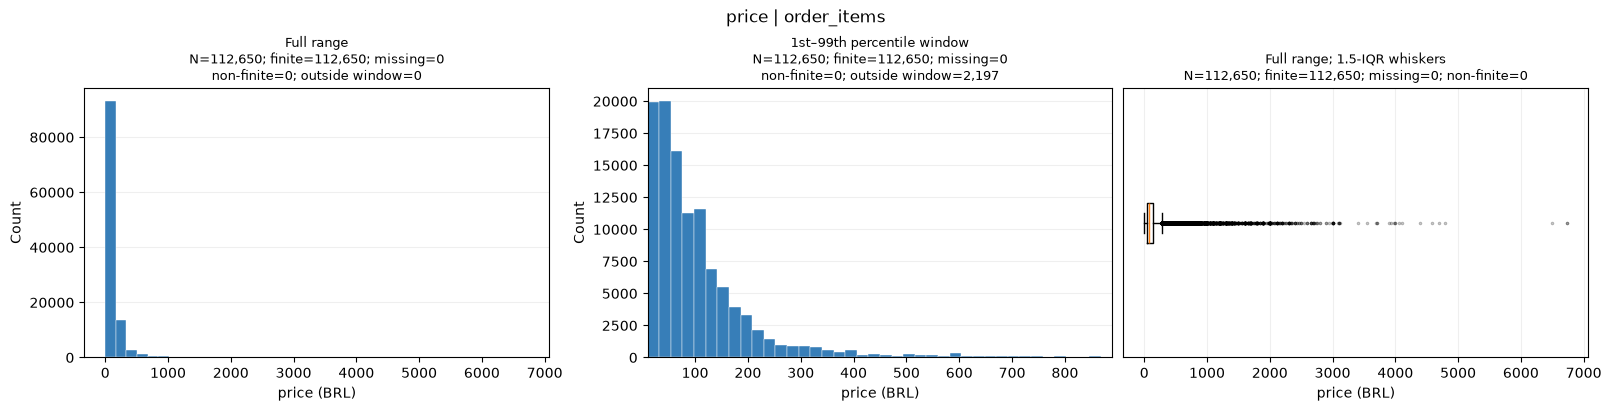

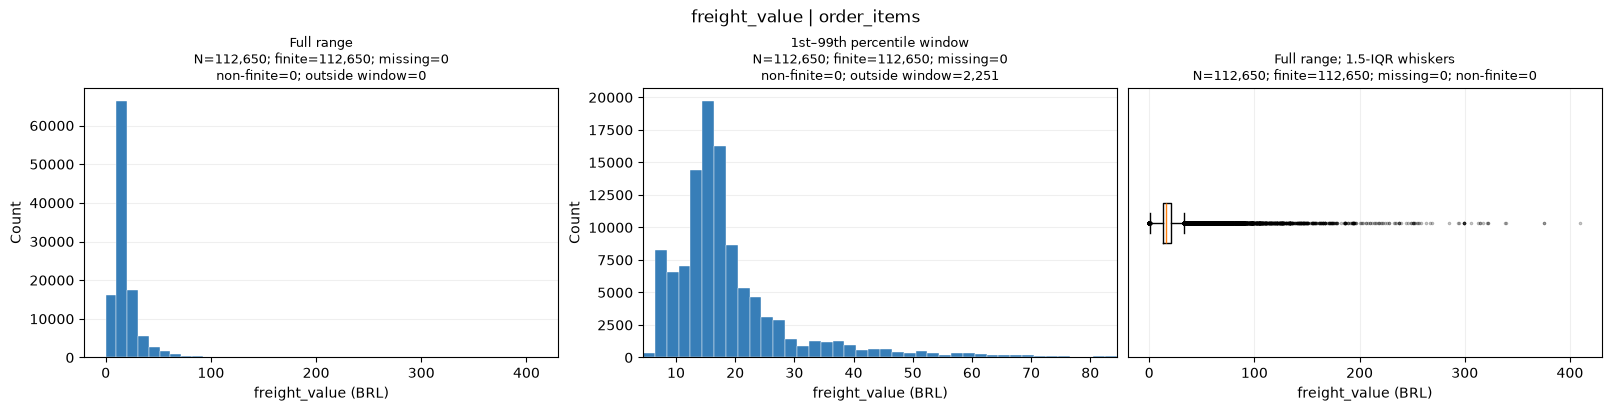

Numeric measurements | products | N=32,951
Counts (missing_pct uses all rows)


column,product_weight_g,product_length_cm,product_height_cm,product_width_cm
rows,32951.00000,32951.00000,32951.00000,32951.00000
finite,32949.00000,32949.00000,32949.00000,32949.00000
missing,2.00000,2.00000,2.00000,2.00000
missing_pct,0.00607,0.00607,0.00607,0.00607
non_finite_non_null,0.00000,0.00000,0.00000,0.00000
zero,4.00000,0.00000,0.00000,0.00000
negative,0.00000,0.00000,0.00000,0.00000


Distribution of finite values


column,product_weight_g,product_length_cm,product_height_cm,product_width_cm
min,0.000000,7.000000,2.000000,6.000000
p01,60.000000,16.000000,2.000000,11.000000
p05,105.000000,16.000000,3.000000,11.000000
p25,300.000000,18.000000,8.000000,15.000000
median,700.000000,25.000000,13.000000,20.000000
p75,1900.000000,38.000000,21.000000,30.000000
p95,10850.000000,65.000000,44.000000,47.000000
p99,22538.000000,100.000000,69.000000,63.000000
max,40425.000000,105.000000,105.000000,118.000000
mean,2276.472488,30.815078,16.937661,23.196728


IQR diagnostics (outside_iqr_pct uses finite values)


column,product_weight_g,product_length_cm,product_height_cm,product_width_cm
iqr,1600.000000,20.000000,13.000000,15.000000
iqr_lower,-2100.000000,-12.000000,-11.500000,-7.500000
iqr_upper,4300.000000,68.000000,40.500000,52.500000
below_iqr,0.000000,0.000000,0.000000,0.000000
above_iqr,4551.000000,1380.000000,1892.000000,912.000000
outside_iqr_pct,13.812255,4.188291,5.742208,2.767914


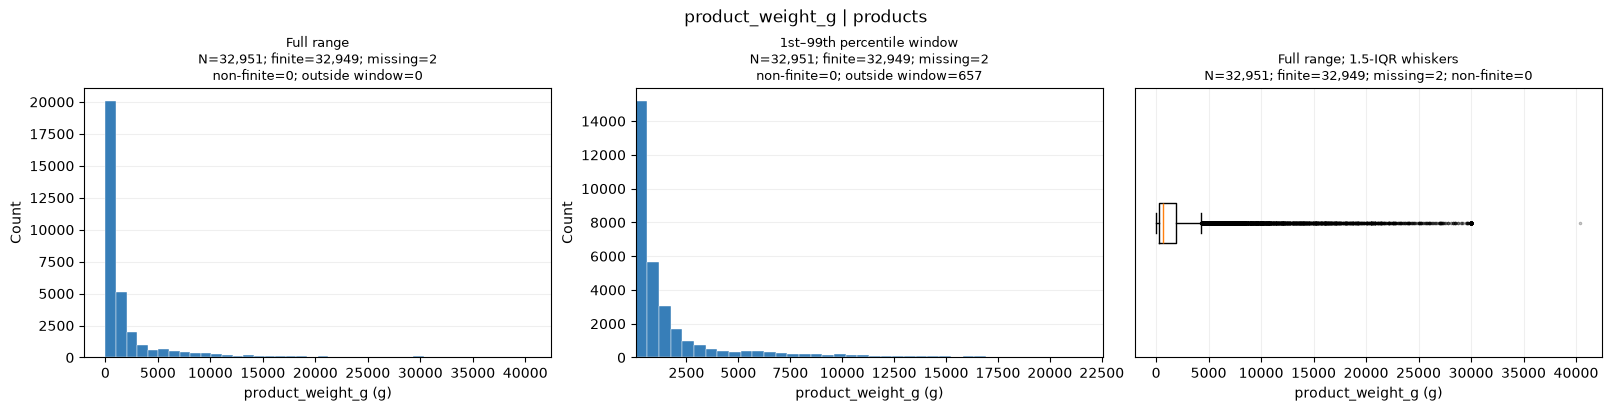

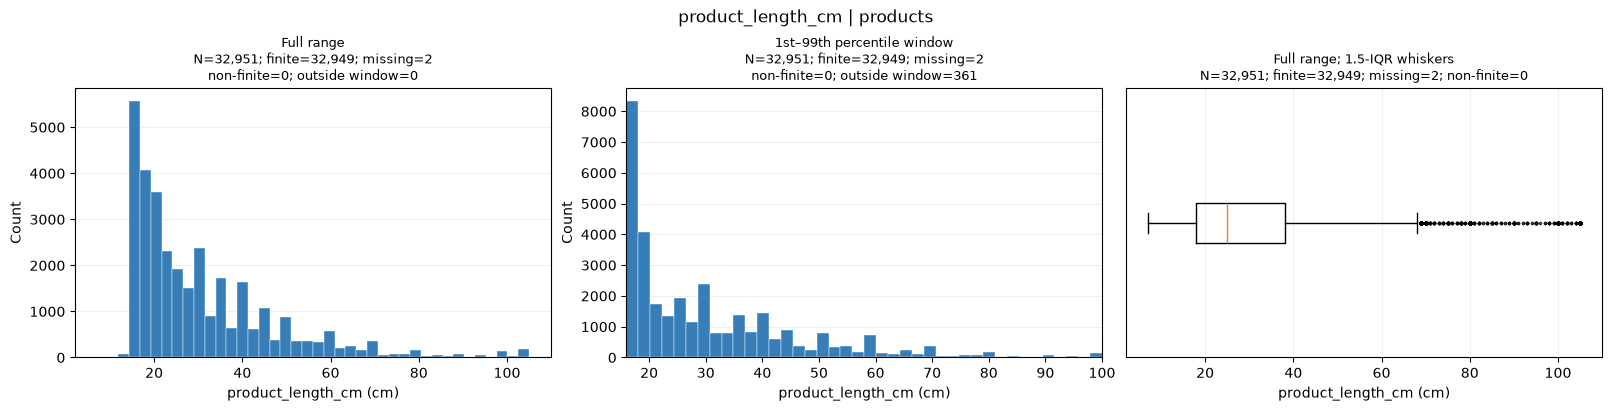

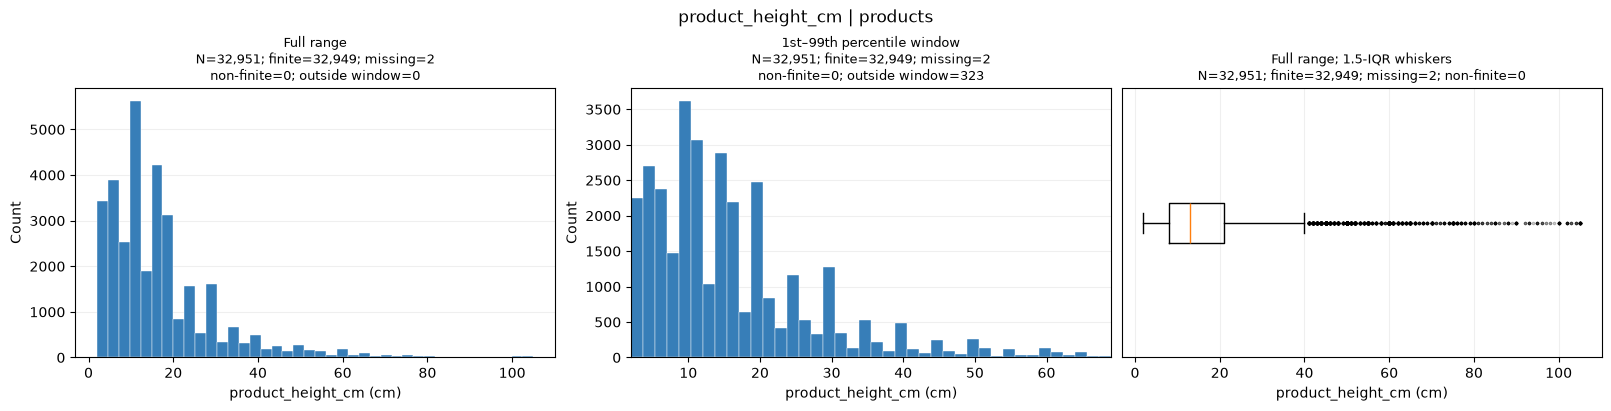

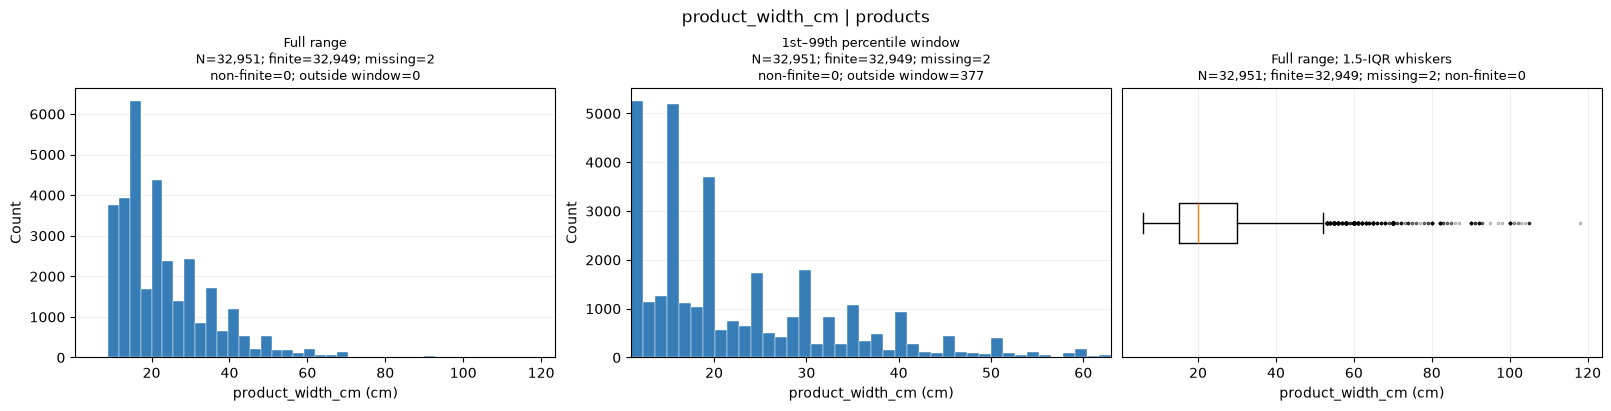

In [25]:
numeric_profiles = inspect_numeric_distributions(
    entity_views=entity_views,
    column_roles=column_roles,
)


### Categories and ZIP prefixes

Status uses order grain; customer and seller locations use their respective entity grain; product category uses product grain.

Complete frequency tables remain available in `category_distributions["frequency_tables"]`. Displays show the top 15 values plus Other, Blank and Missing. Counts retain the full population and original text forms.


order_status | orders | N=98,666; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,delivered,value,96478,98666,97.782417
1,shipped,value,1106,98666,1.120954
2,canceled,value,461,98666,0.467233
3,invoiced,value,312,98666,0.316218
4,processing,value,301,98666,0.305070
5,unavailable,value,6,98666,0.006081
6,approved,value,2,98666,0.002027
7,<NA>,missing,0,98666,0.000000


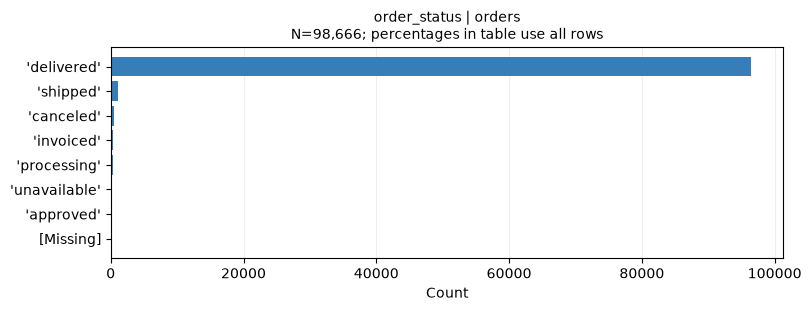

customer_zip_code_prefix | customers | N=98,666; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,22790,value,142,98666,0.143920
1,22793,value,121,98666,0.122636
2,24220,value,121,98666,0.122636
3,24230,value,117,98666,0.118582
4,22775,value,108,98666,0.109460
5,29101,value,101,98666,0.102366
6,13212,value,94,98666,0.095271
7,35162,value,93,98666,0.094257
8,22631,value,88,98666,0.089190
9,38400,value,85,98666,0.086149


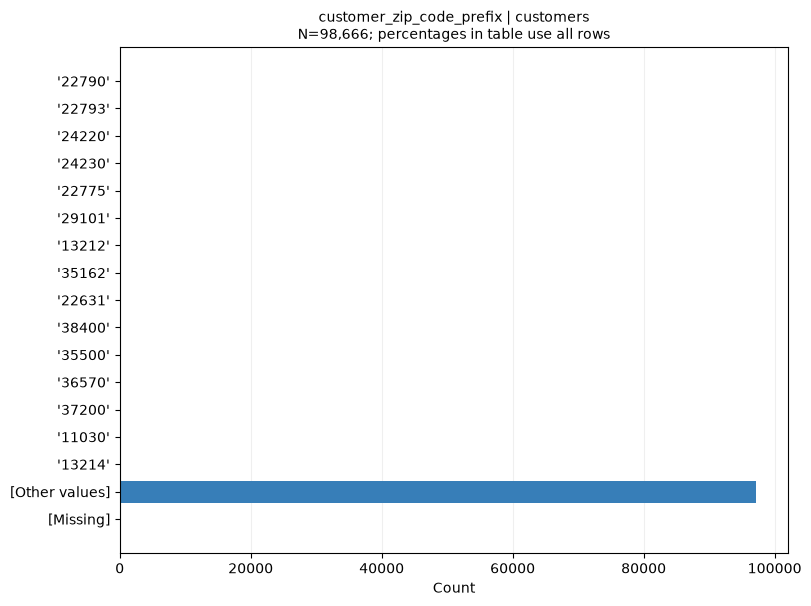

customer_city | customers | N=98,666; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,sao paulo,value,15402,98666,15.610241
1,rio de janeiro,value,6834,98666,6.926398
2,belo horizonte,value,2750,98666,2.787181
3,brasilia,value,2116,98666,2.144609
4,curitiba,value,1510,98666,1.530416
5,campinas,value,1429,98666,1.448321
6,porto alegre,value,1372,98666,1.390550
7,salvador,value,1238,98666,1.254738
8,guarulhos,value,1178,98666,1.193927
9,sao bernardo do campo,value,928,98666,0.940547


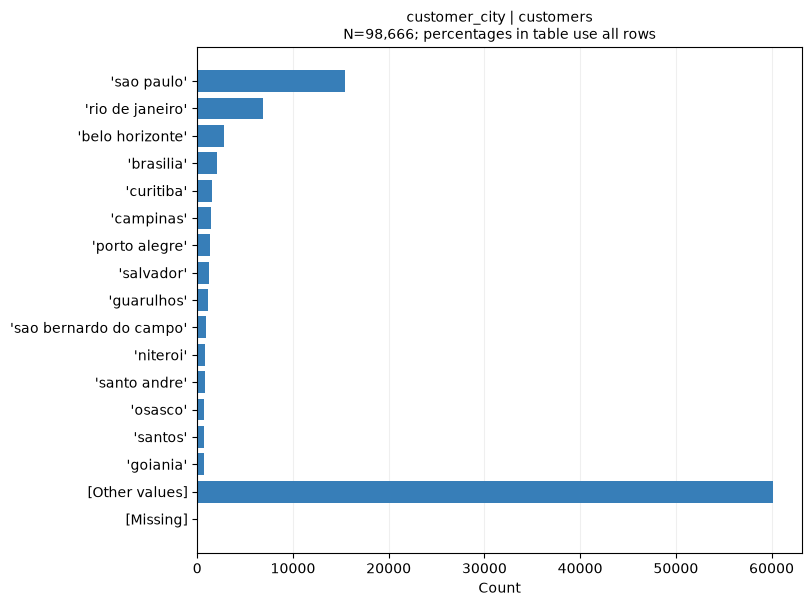

customer_state | customers | N=98,666; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,SP,value,41375,98666,41.934405
1,RJ,value,12762,98666,12.934547
2,MG,value,11544,98666,11.700079
3,RS,value,5432,98666,5.505443
4,PR,value,4998,98666,5.065575
5,SC,value,3612,98666,3.660836
6,BA,value,3358,98666,3.403401
7,DF,value,2125,98666,2.153731
8,ES,value,2025,98666,2.052379
9,GO,value,2007,98666,2.034135


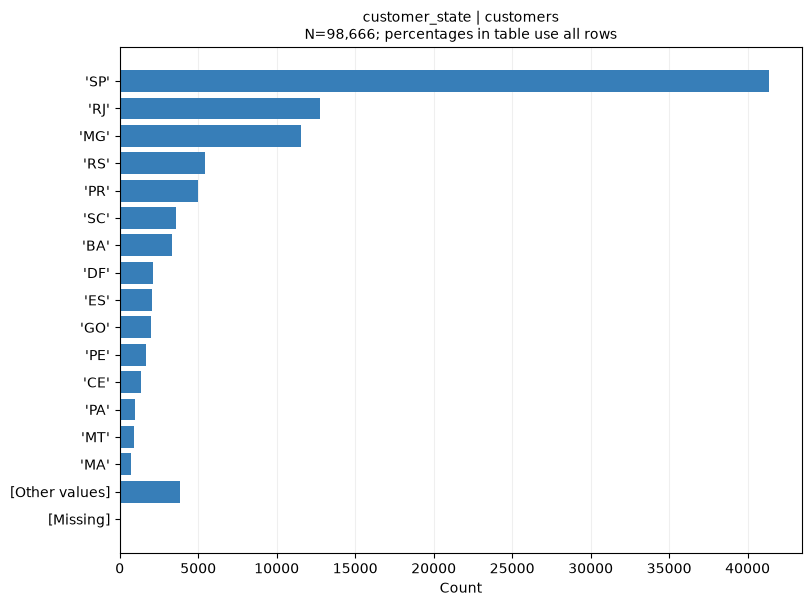

product_category_name | products | N=32,951; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,cama_mesa_banho,value,3029,32951,9.192437
1,esporte_lazer,value,2867,32951,8.700798
2,moveis_decoracao,value,2657,32951,8.063488
3,beleza_saude,value,2444,32951,7.417074
4,utilidades_domesticas,value,2335,32951,7.086280
5,automotivo,value,1900,32951,5.766138
6,informatica_acessorios,value,1639,32951,4.974052
7,brinquedos,value,1411,32951,4.282116
8,relogios_presentes,value,1329,32951,4.033262
9,telefonia,value,1134,32951,3.441474


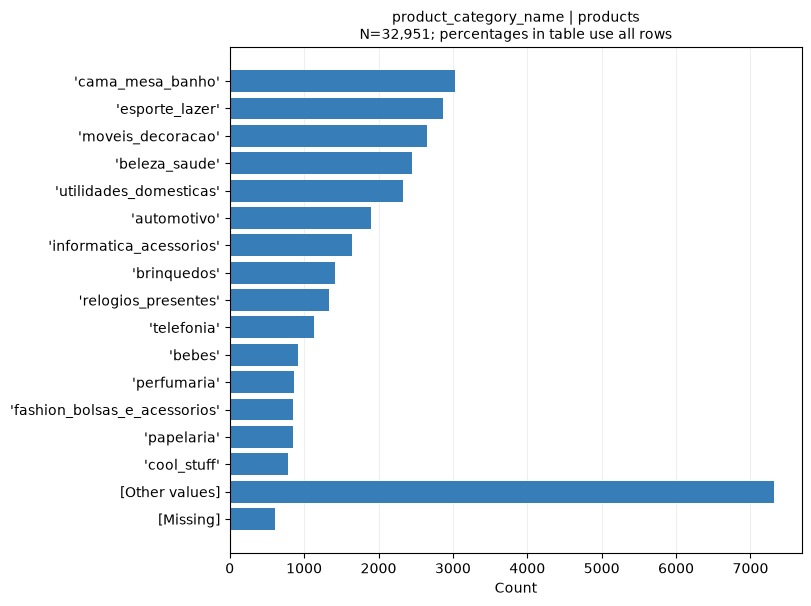

seller_zip_code_prefix | sellers | N=3,095; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,14940,value,49,3095,1.583199
1,13660,value,10,3095,0.323102
2,13920,value,9,3095,0.290792
3,16200,value,9,3095,0.290792
4,01026,value,8,3095,0.258481
5,87050,value,8,3095,0.258481
6,14020,value,8,3095,0.258481
7,37540,value,7,3095,0.226171
8,13481,value,7,3095,0.226171
9,87015,value,6,3095,0.193861


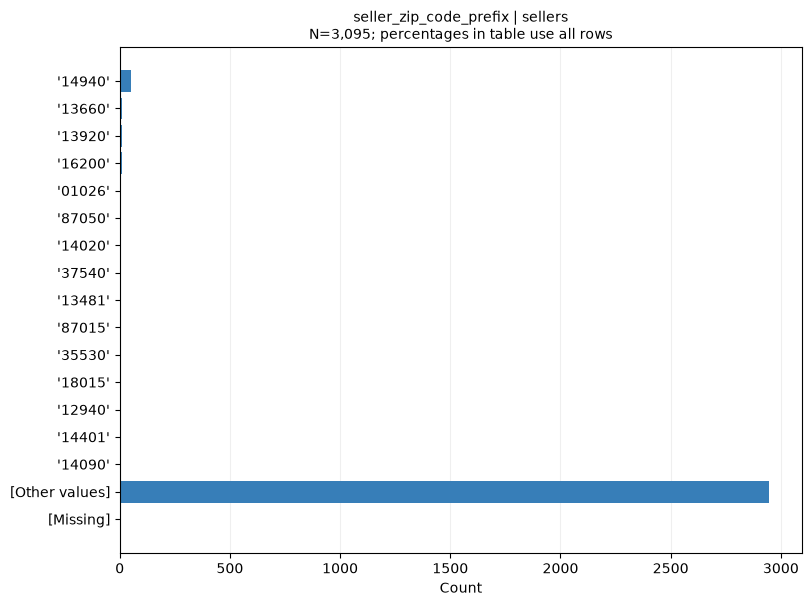

seller_city | sellers | N=3,095; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,sao paulo,value,694,3095,22.423263
1,curitiba,value,127,3095,4.103393
2,rio de janeiro,value,96,3095,3.101777
3,belo horizonte,value,68,3095,2.197092
4,ribeirao preto,value,52,3095,1.680129
5,guarulhos,value,50,3095,1.615509
6,ibitinga,value,49,3095,1.583199
7,santo andre,value,45,3095,1.453958
8,campinas,value,41,3095,1.324717
9,maringa,value,40,3095,1.292407


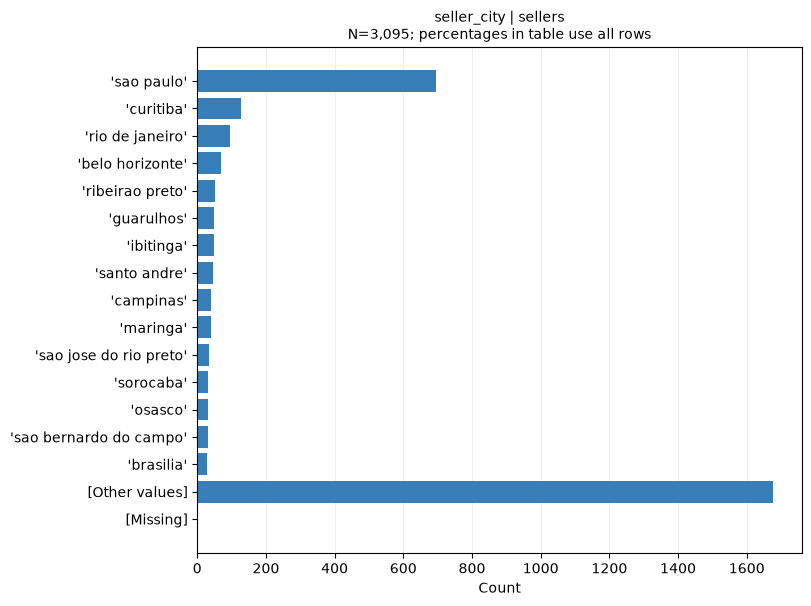

seller_state | sellers | N=3,095; top 15 plus special rows


,value,kind,count,total_rows,pct_all
0,SP,value,1849,3095,59.741519
1,PR,value,349,3095,11.276252
2,MG,value,244,3095,7.883683
3,SC,value,190,3095,6.138934
4,RJ,value,171,3095,5.525040
5,RS,value,129,3095,4.168013
6,GO,value,40,3095,1.292407
7,DF,value,30,3095,0.969305
8,ES,value,23,3095,0.743134
9,BA,value,19,3095,0.613893


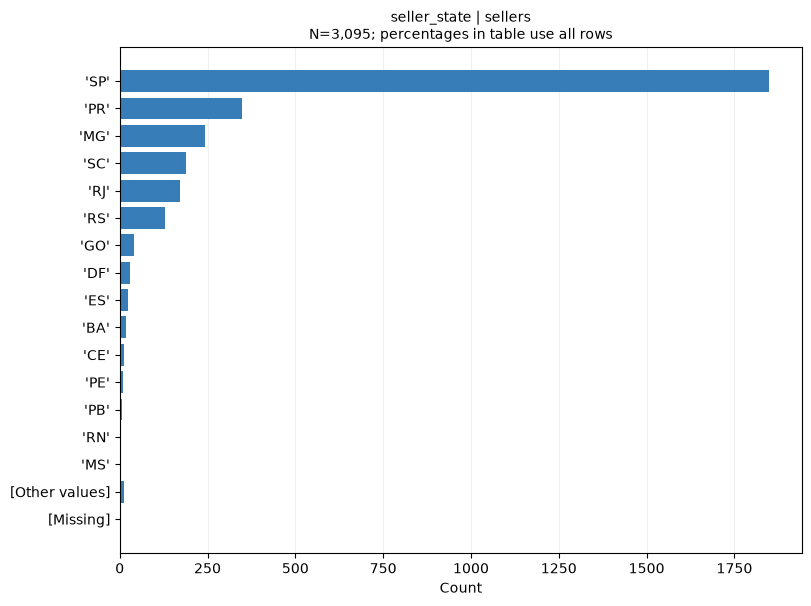

In [26]:
category_distributions = inspect_category_distributions(
    entity_views=entity_views,
    column_roles=column_roles,
)


### Timestamp coverage and calendar distributions

Order timestamps use one row per order. Shipping deadlines use item grain. Coverage includes missingness, range and recorded clock precision; calendar profiles cover month, date, weekday and hour.

Calendar components use the stored clock. Month and date tables contain observed buckets; weekday and hour tables include all seven and 24 buckets. Missing timestamps remain in the all-row denominator. Only date displays are limited to the top 15 dates plus Other and Missing; complete frequencies remain in `temporal_distributions`.


Timestamp coverage | order_items | N=112,650


,column,rows,non_null,missing,missing_pct,min,max,distinct_non_null,non_midnight,subsecond
0,shipping_limit_date,112650,112650,0,0.0,2016-09-19 00:15:34,2020-04-09 22:35:08,93318,112650,0


shipping_limit_date | order_items | month | N=112,650


,value,kind,count,total_rows,pct_all
0,2016-09,value,4,112650,0.003551
1,2016-10,value,365,112650,0.324012
2,2016-12,value,1,112650,0.000888
3,2017-01,value,681,112650,0.604527
4,2017-02,value,1866,112650,1.656458
5,2017-03,value,2751,112650,2.442077
6,2017-04,value,2364,112650,2.098535
7,2017-05,value,4150,112650,3.683977
8,2017-06,value,3801,112650,3.374168
9,2017-07,value,4116,112650,3.653795


shipping_limit_date | order_items | date | N=112,650


,value,kind,count,total_rows,pct_all
0,2017-11-30,value,1647,112650,1.462051
1,2017-12-07,value,752,112650,0.667554
2,2018-04-19,value,709,112650,0.629383
3,2018-05-10,value,673,112650,0.597426
4,2018-01-18,value,661,112650,0.586773
5,2018-03-08,value,653,112650,0.579672
6,2018-08-07,value,653,112650,0.579672
7,2018-02-22,value,651,112650,0.577896
8,2018-03-01,value,644,112650,0.571682
9,2018-03-22,value,632,112650,0.561030


shipping_limit_date | order_items | weekday | N=112,650


,value,kind,count,total_rows,pct_all
0,Monday,value,20750,112650,18.419885
1,Tuesday,value,20079,112650,17.824234
2,Wednesday,value,20638,112650,18.320462
3,Thursday,value,30476,112650,27.053706
4,Friday,value,17487,112650,15.523302
5,Saturday,value,461,112650,0.409232
6,Sunday,value,2759,112650,2.449179
7,NaN,missing,0,112650,0.000000


shipping_limit_date | order_items | hour | N=112,650


,value,kind,count,total_rows,pct_all
0,0,value,2403,112650,2.133156
1,1,value,1649,112650,1.463826
2,2,value,8407,112650,7.462938
3,3,value,6377,112650,5.660897
4,4,value,4082,112650,3.623613
5,5,value,1061,112650,0.941855
6,6,value,1073,112650,0.952508
7,7,value,1600,112650,1.420328
8,8,value,2637,112650,2.340879
9,9,value,4605,112650,4.087883


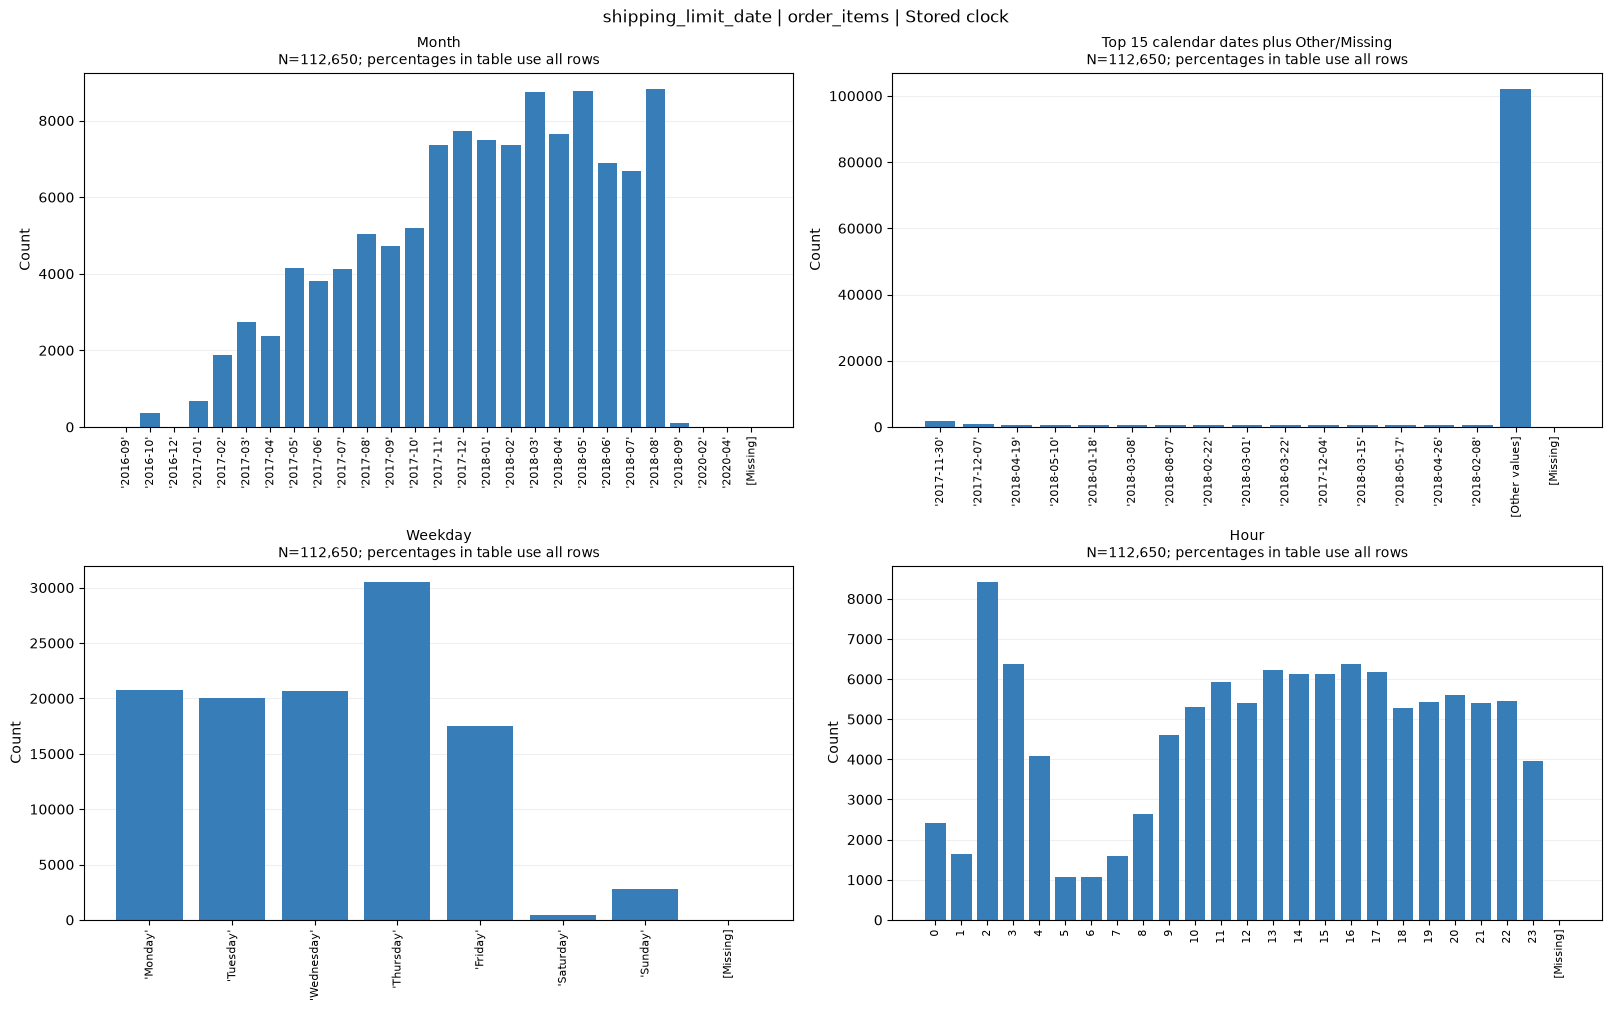

Timestamp coverage | orders | N=98,666


,column,rows,non_null,missing,missing_pct,min,max,distinct_non_null,non_midnight,subsecond
0,order_purchase_timestamp,98666,98666,0,0.000000,2016-09-04 21:15:19,2018-09-03 09:06:57,98112,98665,0
1,order_approved_at,98666,98652,14,0.014189,2016-09-15 12:16:38,2018-09-03 17:40:06,90174,98652,0
2,order_delivered_carrier_date,98666,97657,1009,1.022642,2016-10-08 10:34:01,2018-09-11 19:48:28,81017,97656,0
3,order_delivered_customer_date,98666,96476,2190,2.219610,2016-10-11 13:46:32,2018-10-17 13:22:46,95664,96476,0
4,order_estimated_delivery_date,98666,98666,0,0.000000,2016-10-04 00:00:00,2018-10-25 00:00:00,450,0,0


order_purchase_timestamp | orders | month | N=98,666


,value,kind,count,total_rows,pct_all
0,2016-09,value,3,98666,0.003041
1,2016-10,value,308,98666,0.312164
2,2016-12,value,1,98666,0.001014
3,2017-01,value,789,98666,0.799668
4,2017-02,value,1733,98666,1.756431
5,2017-03,value,2641,98666,2.676707
6,2017-04,value,2391,98666,2.423327
7,2017-05,value,3660,98666,3.709485
8,2017-06,value,3217,98666,3.260495
9,2017-07,value,3969,98666,4.022662


order_purchase_timestamp | orders | date | N=98,666


,value,kind,count,total_rows,pct_all
0,2017-11-24,value,1166,98666,1.181765
1,2017-11-25,value,498,98666,0.504733
2,2017-11-27,value,400,98666,0.405408
3,2017-11-26,value,388,98666,0.393246
4,2017-11-28,value,376,98666,0.381084
5,2018-08-06,value,372,98666,0.377030
6,2018-05-07,value,371,98666,0.376016
7,2018-08-07,value,366,98666,0.370948
8,2018-05-14,value,364,98666,0.368921
9,2018-05-16,value,357,98666,0.361827


order_purchase_timestamp | orders | weekday | N=98,666


,value,kind,count,total_rows,pct_all
0,Monday,value,16068,98666,16.285245
1,Tuesday,value,15831,98666,16.045041
2,Wednesday,value,15425,98666,15.633552
3,Thursday,value,14639,98666,14.836925
4,Friday,value,14002,98666,14.191312
5,Saturday,value,10813,98666,10.959196
6,Sunday,value,11888,98666,12.048730
7,NaN,missing,0,98666,0.000000


order_purchase_timestamp | orders | hour | N=98,666


,value,kind,count,total_rows,pct_all
0,0,value,2378,98666,2.410151
1,1,value,1156,98666,1.171630
2,2,value,505,98666,0.511828
3,3,value,269,98666,0.272637
4,4,value,205,98666,0.207772
5,5,value,187,98666,0.189528
6,6,value,500,98666,0.506760
7,7,value,1223,98666,1.239535
8,8,value,2945,98666,2.984817
9,9,value,4735,98666,4.799019


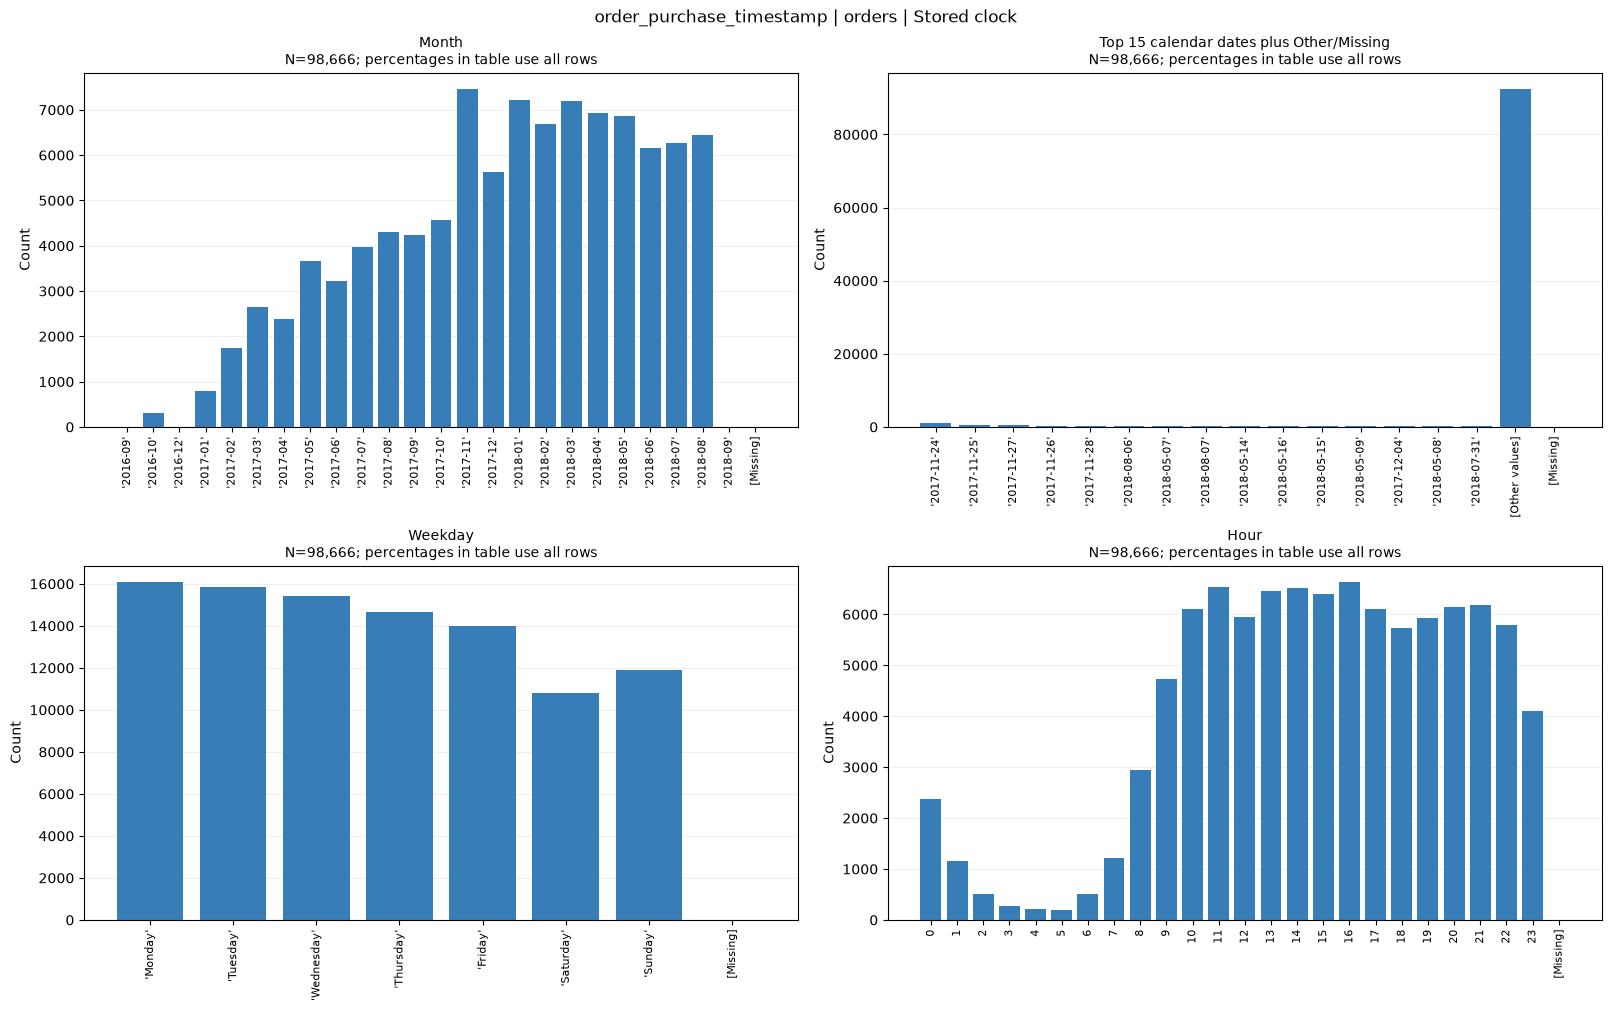

order_approved_at | orders | month | N=98,666


,value,kind,count,total_rows,pct_all
0,2016-09,value,1,98666,0.001014
1,2016-10,value,310,98666,0.314191
2,2016-12,value,1,98666,0.001014
3,2017-01,value,752,98666,0.762167
4,2017-02,value,1718,98666,1.741228
5,2017-03,value,2650,98666,2.685829
6,2017-04,value,2365,98666,2.396976
7,2017-05,value,3661,98666,3.710498
8,2017-06,value,3228,98666,3.271644
9,2017-07,value,3922,98666,3.975027


order_approved_at | orders | date | N=98,666


,value,kind,count,total_rows,pct_all
0,2018-04-24,value,990,98666,1.003385
1,2017-11-24,value,791,98666,0.801695
2,2017-11-25,value,750,98666,0.760140
3,2018-07-05,value,697,98666,0.706424
4,2017-11-28,value,501,98666,0.507774
5,2018-08-07,value,444,98666,0.450003
6,2018-08-20,value,426,98666,0.431760
7,2017-12-05,value,422,98666,0.427706
8,2018-05-08,value,422,98666,0.427706
9,2018-05-01,value,406,98666,0.411489


order_approved_at | orders | weekday | N=98,666


,value,kind,count,total_rows,pct_all
0,Monday,value,12920,98666,13.094683
1,Tuesday,value,19031,98666,19.288306
2,Wednesday,value,15684,98666,15.896053
3,Thursday,value,15373,98666,15.580849
4,Friday,value,14558,98666,14.754829
5,Saturday,value,12118,98666,12.281840
6,Sunday,value,8968,98666,9.089251
7,NaN,missing,14,98666,0.014189


order_approved_at | orders | hour | N=98,666


,value,kind,count,total_rows,pct_all
0,0,value,1956,98666,1.982446
1,1,value,1518,98666,1.538524
2,2,value,7002,98666,7.096670
3,3,value,5496,98666,5.570308
4,4,value,3325,98666,3.369955
5,5,value,1044,98666,1.058115
6,6,value,920,98666,0.932439
7,7,value,1482,98666,1.502037
8,8,value,2246,98666,2.276367
9,9,value,3759,98666,3.809823


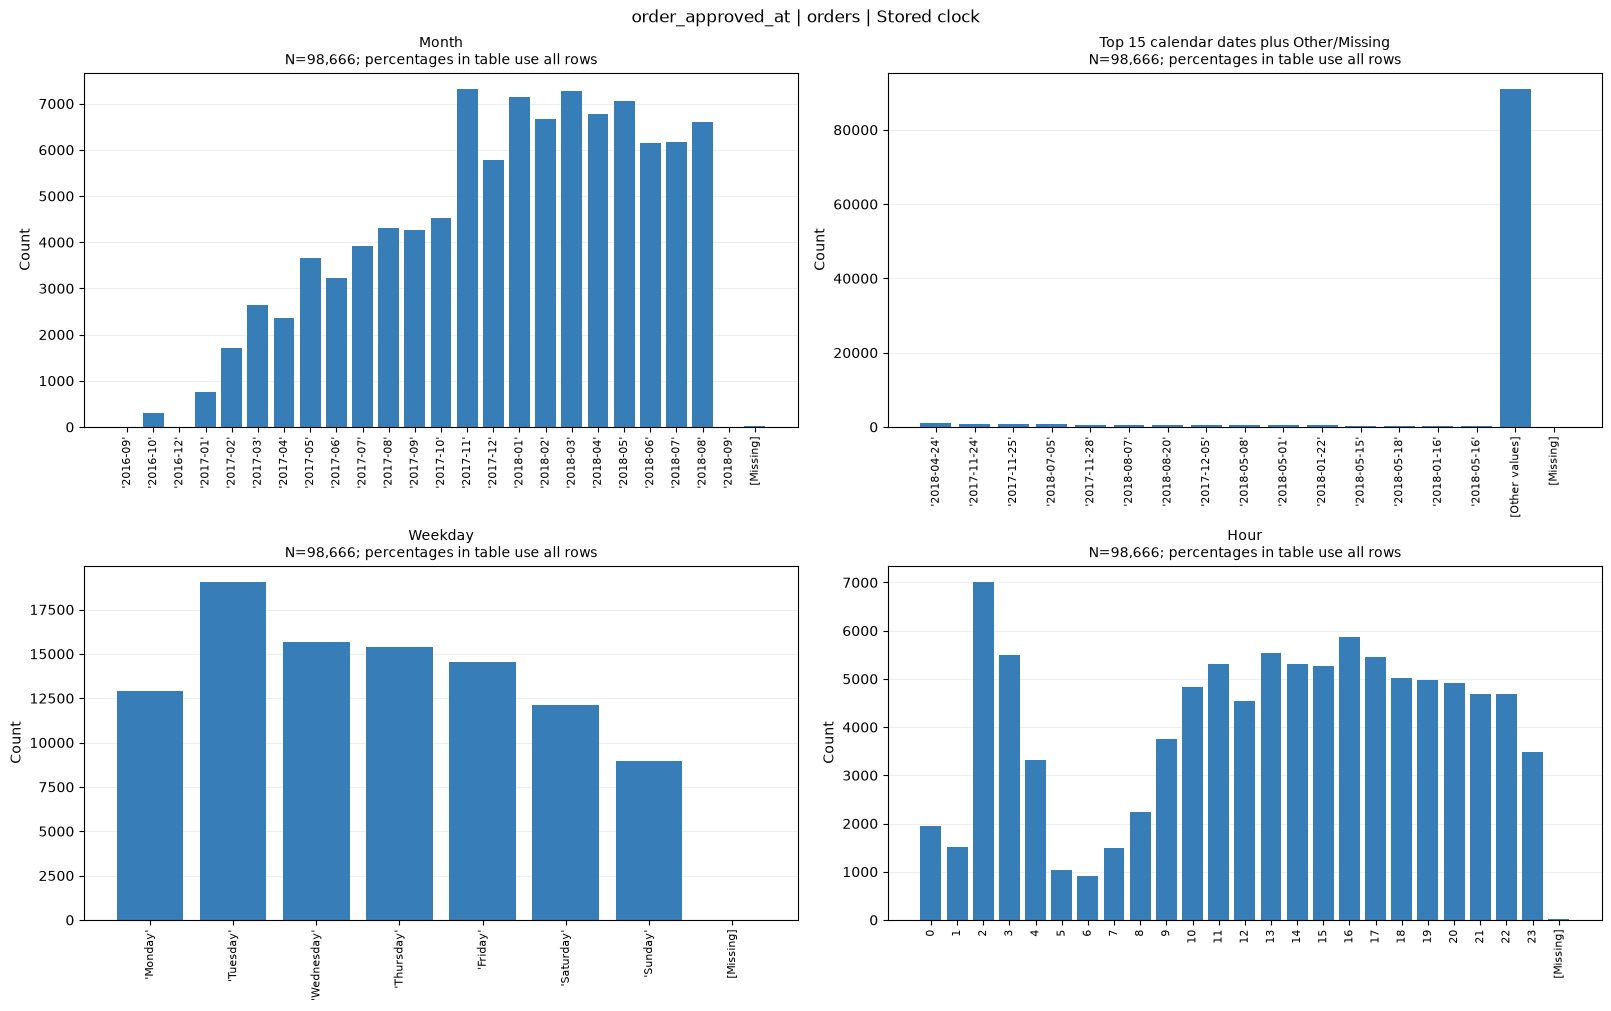

order_delivered_carrier_date | orders | month | N=98,666


,value,kind,count,total_rows,pct_all
0,2016-10,value,247,98666,0.250340
1,2016-11,value,31,98666,0.031419
2,2016-12,value,2,98666,0.002027
3,2017-01,value,612,98666,0.620274
4,2017-02,value,1517,98666,1.537510
5,2017-03,value,2717,98666,2.753735
6,2017-04,value,2141,98666,2.169947
7,2017-05,value,3709,98666,3.759147
8,2017-06,value,3263,98666,3.307117
9,2017-07,value,3710,98666,3.760161


order_delivered_carrier_date | orders | date | N=98,666


,value,kind,count,total_rows,pct_all
0,2017-11-28,value,707,98666,0.716559
1,2017-11-27,value,673,98666,0.682099
2,2017-11-29,value,566,98666,0.573653
3,2018-02-27,value,523,98666,0.530071
4,2018-03-27,value,511,98666,0.517909
5,2018-08-06,value,510,98666,0.516895
6,2017-11-30,value,489,98666,0.495611
7,2018-08-13,value,472,98666,0.478382
8,2018-05-15,value,451,98666,0.457098
9,2018-05-03,value,450,98666,0.456084


order_delivered_carrier_date | orders | weekday | N=98,666


,value,kind,count,total_rows,pct_all
0,Monday,value,19864,98666,20.132568
1,Tuesday,value,21803,98666,22.097784
2,Wednesday,value,19808,98666,20.075811
3,Thursday,value,17190,98666,17.422415
4,Friday,value,17160,98666,17.392009
5,Saturday,value,1795,98666,1.819269
6,Sunday,value,37,98666,0.037500
7,NaN,missing,1009,98666,1.022642


order_delivered_carrier_date | orders | hour | N=98,666


,value,kind,count,total_rows,pct_all
0,0,value,2445,98666,2.478057
1,1,value,1366,98666,1.384469
2,2,value,618,98666,0.626356
3,3,value,273,98666,0.276691
4,4,value,168,98666,0.170271
5,5,value,277,98666,0.280745
6,6,value,688,98666,0.697302
7,7,value,1043,98666,1.057102
8,8,value,1954,98666,1.980419
9,9,value,2526,98666,2.560152


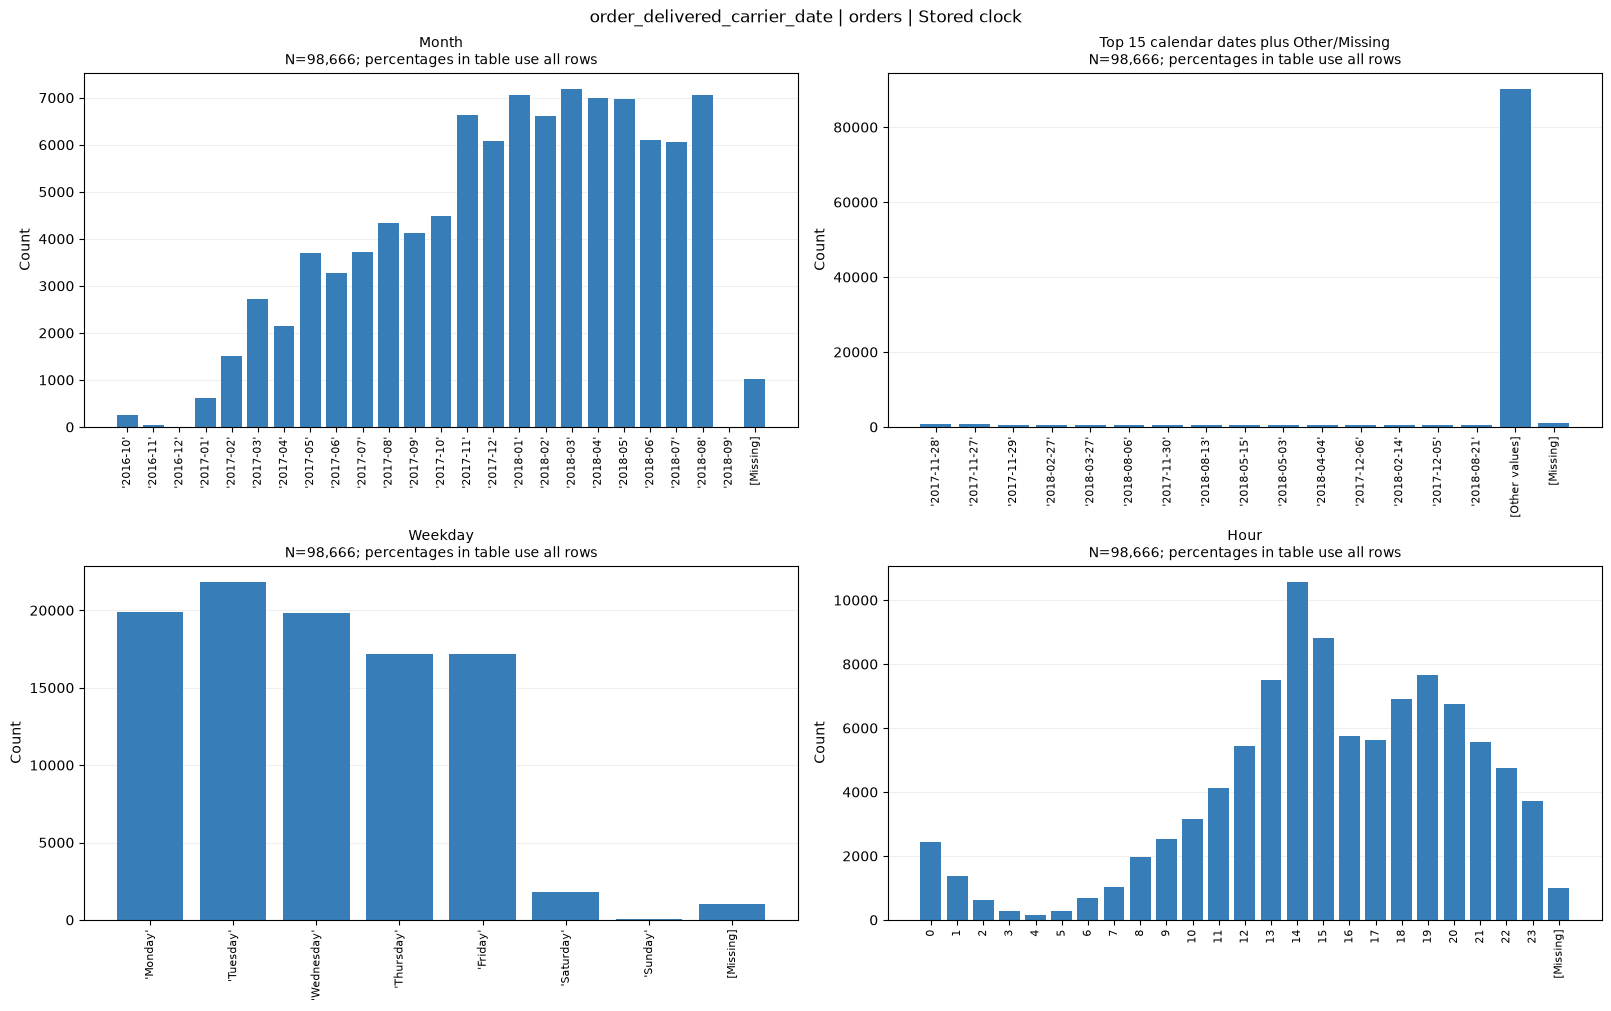

order_delivered_customer_date | orders | month | N=98,666


,value,kind,count,total_rows,pct_all
0,2016-10,value,208,98666,0.210812
1,2016-11,value,60,98666,0.060811
2,2016-12,value,4,98666,0.004054
3,2017-01,value,283,98666,0.286826
4,2017-02,value,1351,98666,1.369266
5,2017-03,value,2382,98666,2.414206
6,2017-04,value,1849,98666,1.873999
7,2017-05,value,3751,98666,3.801715
8,2017-06,value,3223,98666,3.266576
9,2017-07,value,3455,98666,3.501713


order_delivered_customer_date | orders | date | N=98,666


,value,kind,count,total_rows,pct_all
0,2018-08-27,value,446,98666,0.452030
1,2018-08-13,value,442,98666,0.447976
2,2018-05-14,value,434,98666,0.439868
3,2018-05-21,value,431,98666,0.436827
4,2018-05-18,value,425,98666,0.430746
5,2018-04-11,value,413,98666,0.418584
6,2017-12-11,value,412,98666,0.417570
7,2018-07-03,value,410,98666,0.415543
8,2018-05-03,value,409,98666,0.414530
9,2017-06-19,value,405,98666,0.410476


order_delivered_customer_date | orders | weekday | N=98,666


,value,kind,count,total_rows,pct_all
0,Monday,value,18892,98666,19.147427
1,Tuesday,value,18493,98666,18.743032
2,Wednesday,value,18059,98666,18.303164
3,Thursday,value,17097,98666,17.328158
4,Friday,value,17265,98666,17.498429
5,Saturday,value,5463,98666,5.536862
6,Sunday,value,1207,98666,1.223319
7,NaN,missing,2190,98666,2.219610


order_delivered_customer_date | orders | hour | N=98,666


,value,kind,count,total_rows,pct_all
0,0,value,2885,98666,2.924006
1,1,value,1515,98666,1.535483
2,2,value,649,98666,0.657775
3,3,value,260,98666,0.263515
4,4,value,187,98666,0.189528
5,5,value,198,98666,0.200677
6,6,value,269,98666,0.272637
7,7,value,396,98666,0.401354
8,8,value,779,98666,0.789532
9,9,value,1196,98666,1.212170


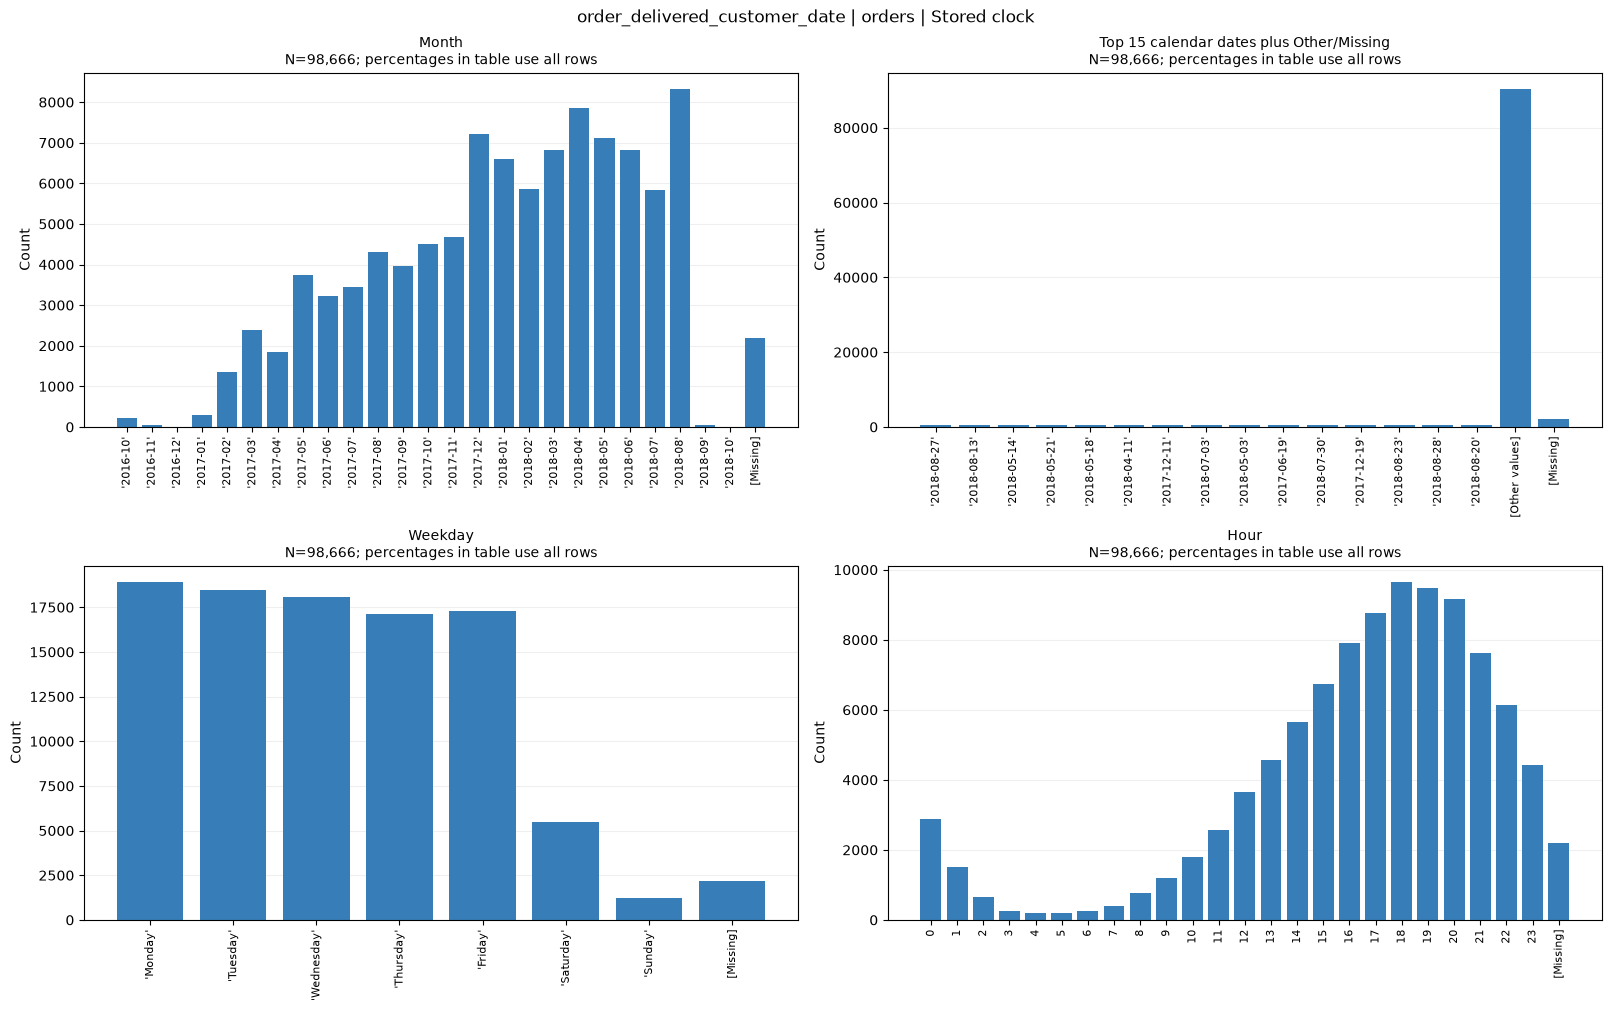

order_estimated_delivery_date | orders | month | N=98,666


,value,kind,count,total_rows,pct_all
0,2016-10,value,5,98666,0.005068
1,2016-11,value,159,98666,0.161150
2,2016-12,value,145,98666,0.146960
3,2017-01,value,3,98666,0.003041
4,2017-02,value,313,98666,0.317232
5,2017-03,value,2732,98666,2.768938
6,2017-04,value,2208,98666,2.237853
7,2017-05,value,3013,98666,3.053737
8,2017-06,value,3604,98666,3.652727
9,2017-07,value,3290,98666,3.334482


order_estimated_delivery_date | orders | date | N=98,666


,value,kind,count,total_rows,pct_all
0,2017-12-20,value,515,98666,0.521963
1,2018-03-12,value,514,98666,0.520949
2,2018-05-29,value,510,98666,0.516895
3,2018-03-13,value,507,98666,0.513855
4,2018-02-14,value,504,98666,0.510814
5,2018-05-28,value,491,98666,0.497638
6,2018-07-05,value,490,98666,0.496625
7,2018-03-06,value,489,98666,0.495611
8,2018-04-12,value,489,98666,0.495611
9,2018-07-18,value,489,98666,0.495611


order_estimated_delivery_date | orders | weekday | N=98,666


,value,kind,count,total_rows,pct_all
0,Monday,value,18987,98666,19.243711
1,Tuesday,value,19502,98666,19.765674
2,Wednesday,value,20228,98666,20.501490
3,Thursday,value,20047,98666,20.318043
4,Friday,value,19902,98666,20.171082
5,Saturday,value,0,98666,0.000000
6,Sunday,value,0,98666,0.000000
7,NaN,missing,0,98666,0.000000


order_estimated_delivery_date | orders | hour | N=98,666


,value,kind,count,total_rows,pct_all
0,0,value,98666,98666,100.0
1,1,value,0,98666,0.0
2,2,value,0,98666,0.0
3,3,value,0,98666,0.0
4,4,value,0,98666,0.0
5,5,value,0,98666,0.0
6,6,value,0,98666,0.0
7,7,value,0,98666,0.0
8,8,value,0,98666,0.0
9,9,value,0,98666,0.0


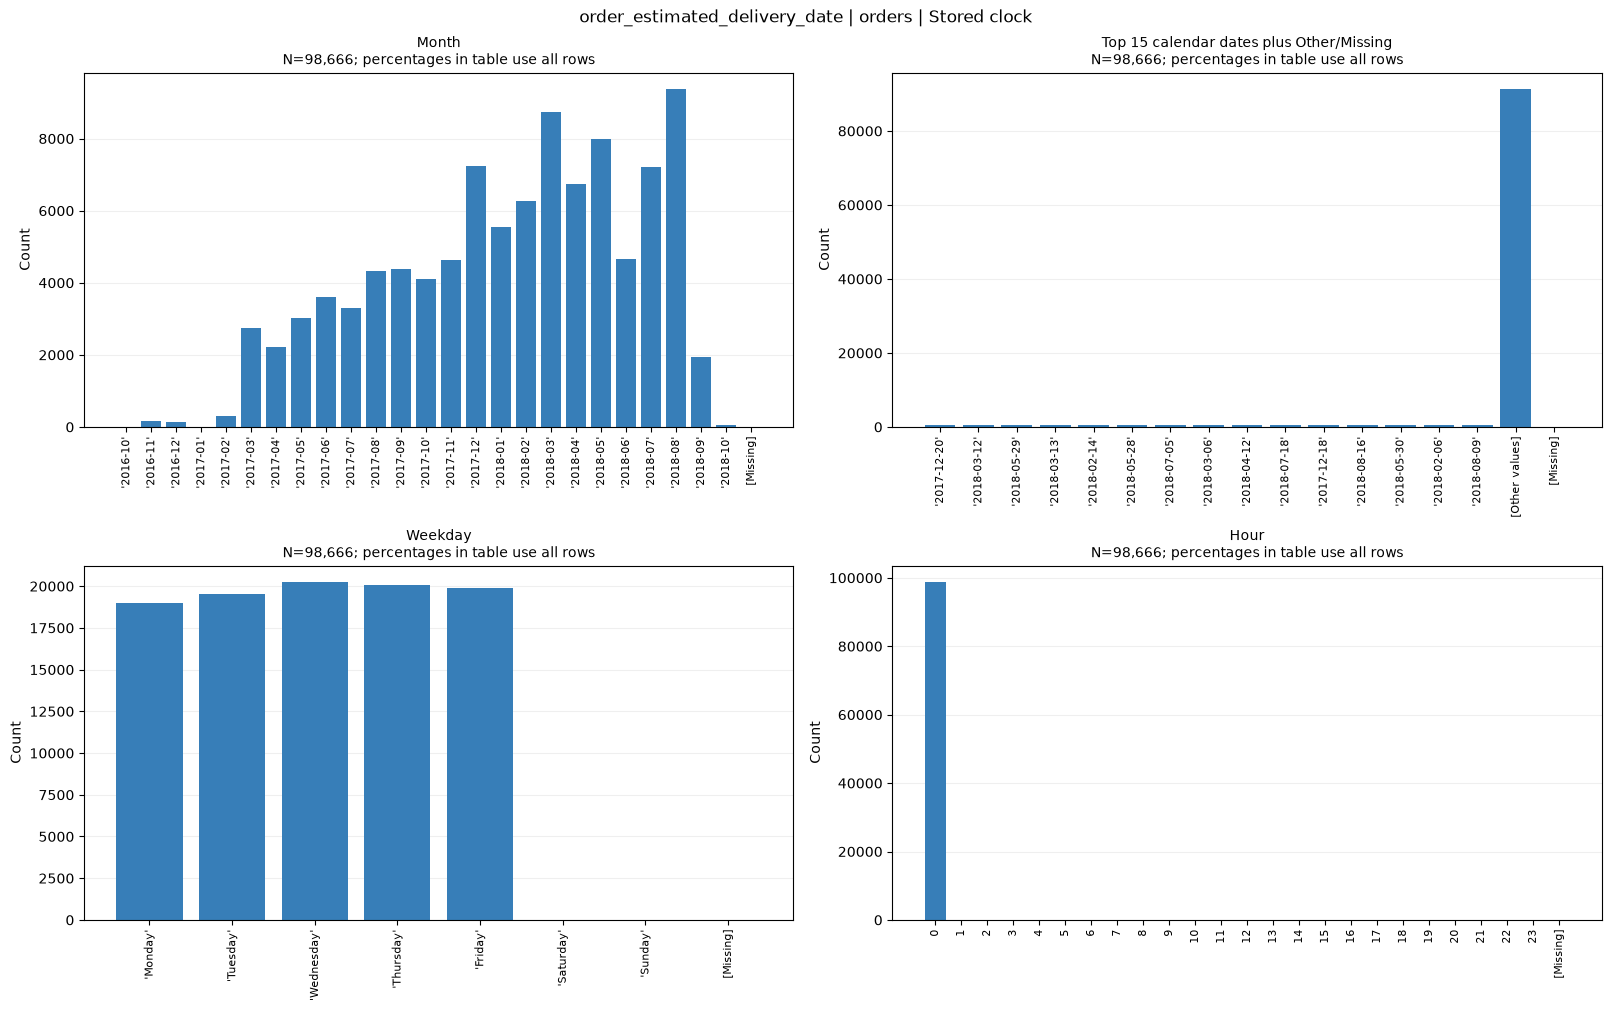

In [27]:
temporal_distributions = inspect_temporal_distributions(
    entity_views=entity_views,
    column_roles=column_roles,
)


## 4. Missingness in context

### Exact patterns and source-grain completeness

Inspect missingness in the 25-column item table and in order, product, customer and seller views. Each row contributes once to a missing-count bin and once to an exact pattern; `()` denotes a complete row within the selected columns.

Percentages use all rows of the named view. Complete result tables, including zero-count bins, remain in `missing_patterns`. Blanks remain separate from nulls.


In [28]:
missing_patterns = inspect_missing_patterns(
    df=df,
    entity_views=entity_views,
    column_profile=column_profile,
)


full_items | N=112,650 | 25 selected columns
Columns with missing values (all counts at this view's grain)


,column,rows,missing,missing_pct,blank,blank_pct
10,order_approved_at,112650,15,0.013316,0,0.0
11,order_delivered_carrier_date,112650,1194,1.059920,0,0.0
12,order_delivered_customer_date,112650,2454,2.178429,0,0.0
17,product_category_name,112650,1603,1.422992,0,0.0
18,product_weight_g,112650,18,0.015979,0,0.0
19,product_length_cm,112650,18,0.015979,0,0.0
20,product_height_cm,112650,18,0.015979,0,0.0
21,product_width_cm,112650,18,0.015979,0,0.0


Observed missing-count bins


,missing_columns_per_row,rows,total_rows,pct_all
0,0,108643,112650,96.442965
1,1,2766,112650,2.455393
2,2,1186,112650,1.052818
3,3,37,112650,0.032845
4,4,1,112650,0.000888
5,5,17,112650,0.015091


All observed exact patterns; () means complete within the selection


,missing_columns,missing_count,rows,total_rows,pct_all
0,(),0,108643,112650,96.442965
1,"(product_category_name,)",1,1519,112650,1.348424
2,"(order_delivered_customer_date,)",1,1232,112650,1.093653
3,"(order_delivered_carrier_date, order_delivered_customer_date)",2,1156,112650,1.026187
4,"(order_delivered_carrier_date, order_delivered_customer_date, product_category_name)",3,37,112650,0.032845
5,"(order_delivered_customer_date, product_category_name)",2,29,112650,0.025743
6,"(product_category_name, product_weight_g, product_length_cm, product_height_cm, product_width_cm)",5,17,112650,0.015091
7,"(order_approved_at,)",1,14,112650,0.012428
8,"(order_delivered_carrier_date,)",1,1,112650,0.000888
9,"(order_approved_at, product_category_name)",2,1,112650,0.000888


... (16 outputs left out)

sellers | N=3,095 | 4 selected columns
Columns with missing values (all counts at this view's grain)
No missing values at this grain.
Observed missing-count bins


,missing_columns_per_row,rows,total_rows,pct_all
0,0,3095,3095,100.0


All observed exact patterns; () means complete within the selection


,missing_columns,missing_count,rows,total_rows,pct_all
0,(),0,3095,3095,100.0


### Paired and directional missingness

Retain every column pair for full items, orders and products. Display pairs involving columns with observed missingness, including pairs with zero jointly missing rows.

Pair counts partition the population into four states. Heatmap rows condition on a column being missing; columns show the percentage also missing another column. Undefined denominators remain NA. Directional percentages may differ.


full_items | N=112,650 | 300 total pairs; 28 displayed
Pair counts (four states sum to N)


,left,right,rows,both_missing,left_only_missing,right_only_missing,both_present
195,order_approved_at,order_delivered_carrier_date,112650,0,15,1194,111441
196,order_approved_at,order_delivered_customer_date,112650,0,15,2454,110181
201,order_approved_at,product_category_name,112650,1,14,1602,111033
202,order_approved_at,product_weight_g,112650,0,15,18,112617
203,order_approved_at,product_length_cm,112650,0,15,18,112617
204,order_approved_at,product_height_cm,112650,0,15,18,112617
205,order_approved_at,product_width_cm,112650,0,15,18,112617
209,order_delivered_carrier_date,order_delivered_customer_date,112650,1193,1,1261,110195
214,order_delivered_carrier_date,product_category_name,112650,37,1157,1566,109890
215,order_delivered_carrier_date,product_weight_g,112650,0,1194,18,111438


Conditional percentages with explicit missing-row denominators


,left,right,left_missing,right_missing,right_missing_given_left_pct,left_missing_given_right_pct
195,order_approved_at,order_delivered_carrier_date,15,1194,0.000000,0.000000
196,order_approved_at,order_delivered_customer_date,15,2454,0.000000,0.000000
201,order_approved_at,product_category_name,15,1603,6.666667,0.062383
202,order_approved_at,product_weight_g,15,18,0.000000,0.000000
203,order_approved_at,product_length_cm,15,18,0.000000,0.000000
204,order_approved_at,product_height_cm,15,18,0.000000,0.000000
205,order_approved_at,product_width_cm,15,18,0.000000,0.000000
209,order_delivered_carrier_date,order_delivered_customer_date,1194,2454,99.916248,48.614507
214,order_delivered_carrier_date,product_category_name,1194,1603,3.098827,2.308172
215,order_delivered_carrier_date,product_weight_g,1194,18,0.000000,0.000000


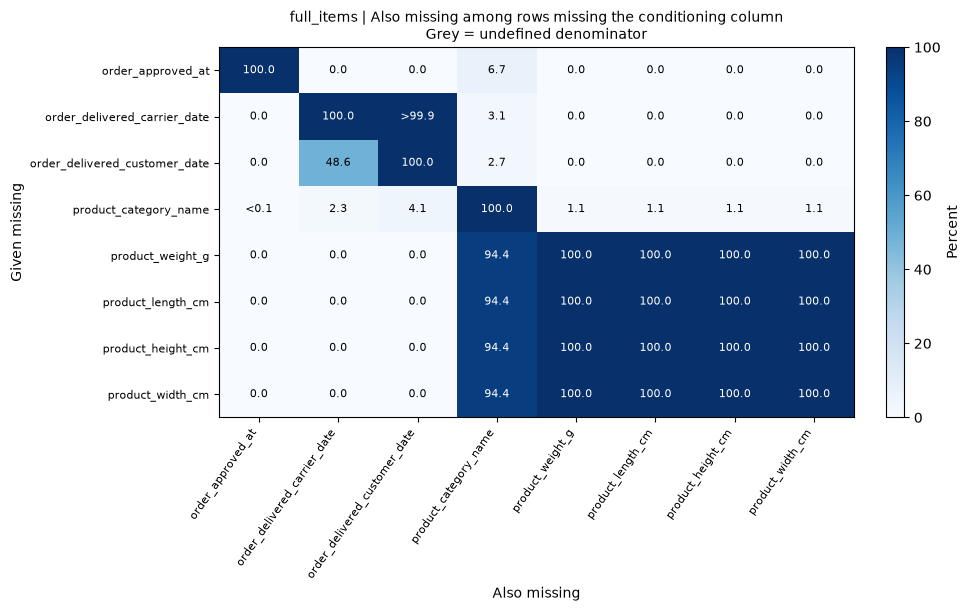

orders | N=98,666 | 28 total pairs; 3 displayed
Pair counts (four states sum to N)


,left,right,rows,both_missing,left_only_missing,right_only_missing,both_present
22,order_approved_at,order_delivered_carrier_date,98666,0,14,1009,97643
23,order_approved_at,order_delivered_customer_date,98666,0,14,2190,96462
25,order_delivered_carrier_date,order_delivered_customer_date,98666,1008,1,1182,96475


Conditional percentages with explicit missing-row denominators


,left,right,left_missing,right_missing,right_missing_given_left_pct,left_missing_given_right_pct
22,order_approved_at,order_delivered_carrier_date,14,1009,0.000000,0.000000
23,order_approved_at,order_delivered_customer_date,14,2190,0.000000,0.000000
25,order_delivered_carrier_date,order_delivered_customer_date,1009,2190,99.900892,46.027397


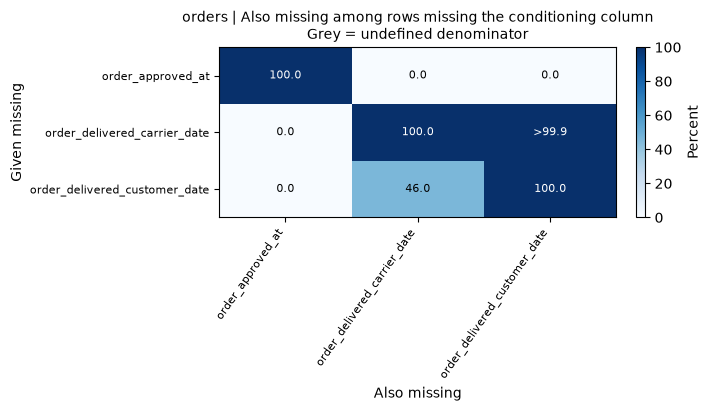

products | N=32,951 | 15 total pairs; 10 displayed
Pair counts (four states sum to N)


,left,right,rows,both_missing,left_only_missing,right_only_missing,both_present
5,product_category_name,product_weight_g,32951,1,609,1,32340
6,product_category_name,product_length_cm,32951,1,609,1,32340
7,product_category_name,product_height_cm,32951,1,609,1,32340
8,product_category_name,product_width_cm,32951,1,609,1,32340
9,product_weight_g,product_length_cm,32951,2,0,0,32949
10,product_weight_g,product_height_cm,32951,2,0,0,32949
11,product_weight_g,product_width_cm,32951,2,0,0,32949
12,product_length_cm,product_height_cm,32951,2,0,0,32949
13,product_length_cm,product_width_cm,32951,2,0,0,32949
14,product_height_cm,product_width_cm,32951,2,0,0,32949


Conditional percentages with explicit missing-row denominators


,left,right,left_missing,right_missing,right_missing_given_left_pct,left_missing_given_right_pct
5,product_category_name,product_weight_g,610,2,0.163934,50.0
6,product_category_name,product_length_cm,610,2,0.163934,50.0
7,product_category_name,product_height_cm,610,2,0.163934,50.0
8,product_category_name,product_width_cm,610,2,0.163934,50.0
9,product_weight_g,product_length_cm,2,2,100.000000,100.0
10,product_weight_g,product_height_cm,2,2,100.000000,100.0
11,product_weight_g,product_width_cm,2,2,100.000000,100.0
12,product_length_cm,product_height_cm,2,2,100.000000,100.0
13,product_length_cm,product_width_cm,2,2,100.000000,100.0
14,product_height_cm,product_width_cm,2,2,100.000000,100.0


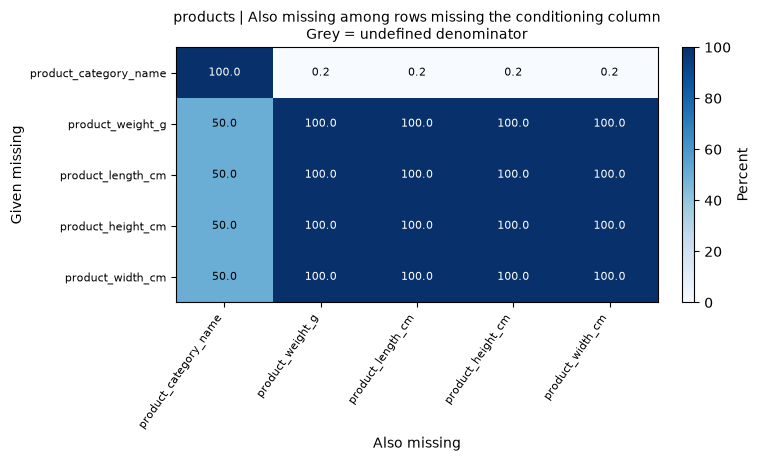

In [29]:
missing_pair_profiles = inspect_missing_pairs(
    missingness_frames=missing_patterns["missingness_frames"],
    native_column_profiles=missing_patterns["native_column_profiles"],
)


### Missingness within observed groups

Group order-timestamp missingness by status, purchase month and customer state. Group product completeness by category and item-level exposure by seller and geography. Purchase month is a temporary calendar grouping.

Missing grouping keys remain included. Each table retains group size, evaluated, unknown and affected counts with explicit denominators. Full groups remain in `missing_context["condition_profiles"]`; limited displays state how many groups are shown.


In [30]:
missing_context = inspect_conditional_missingness(
    column_roles=column_roles,
    df=df,
    entity_views=entity_views,
)


Missing order_purchase_timestamp | grain=orders | grouped by ['order_status']
All-group N=98,666; affected=0; showing 7 of 7 groups; omitted groups=0


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
5,approved,2,2,0,0,0.0,0.0
2,canceled,461,461,0,0,0.0,0.0
0,delivered,96478,96478,0,0,0.0,0.0
3,invoiced,312,312,0,0,0.0,0.0
4,processing,301,301,0,0,0.0,0.0
1,shipped,1106,1106,0,0,0.0,0.0
6,unavailable,6,6,0,0,0.0,0.0


Missing order_approved_at | grain=orders | grouped by ['order_status']
All-group N=98,666; affected=14; showing 7 of 7 groups; omitted groups=0


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
5,approved,2,2,0,0,0.000000,0.000000
2,canceled,461,461,0,0,0.000000,0.000000
0,delivered,96478,96478,0,14,0.014511,0.014511
3,invoiced,312,312,0,0,0.000000,0.000000
4,processing,301,301,0,0,0.000000,0.000000
1,shipped,1106,1106,0,0,0.000000,0.000000
6,unavailable,6,6,0,0,0.000000,0.000000


Missing order_delivered_carrier_date | grain=orders | grouped by ['order_status']
All-group N=98,666; affected=1,009; showing 7 of 7 groups; omitted groups=0


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
5,approved,2,2,0,2,100.000000,100.000000
2,canceled,461,461,0,386,83.731020,83.731020
0,delivered,96478,96478,0,2,0.002073,0.002073
3,invoiced,312,312,0,312,100.000000,100.000000
4,processing,301,301,0,301,100.000000,100.000000
1,shipped,1106,1106,0,0,0.000000,0.000000
6,unavailable,6,6,0,6,100.000000,100.000000


... (20 outputs left out)

Missing any_product_measurement | grain=items | grouped by ['customer_state']
All-group N=112,650; affected=18; showing 27 of 27 groups; omitted groups=0


,customer_state,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
25,AC,92,92,0,0,0.000000,0.000000
6,AL,444,444,0,0,0.000000,0.000000
18,AM,165,165,0,0,0.000000,0.000000
19,AP,82,82,0,0,0.000000,0.000000
5,BA,3799,3799,0,0,0.000000,0.000000
8,CE,1478,1478,0,0,0.000000,0.000000
9,DF,2406,2406,0,1,0.041563,0.041563
13,ES,2256,2256,0,0,0.000000,0.000000
4,GO,2333,2333,0,0,0.000000,0.000000
14,MA,824,824,0,0,0.000000,0.000000


Conditional-profile overview


,Missing target,Grain,Grouping,Rows,Affected rows,Groups,Displayed groups
0,order_purchase_timestamp,orders,"(order_status,)",98666,0,7,7
1,order_approved_at,orders,"(order_status,)",98666,14,7,7
2,order_delivered_carrier_date,orders,"(order_status,)",98666,1009,7,7
3,order_delivered_customer_date,orders,"(order_status,)",98666,2190,7,7
4,order_estimated_delivery_date,orders,"(order_status,)",98666,0,7,7
5,any_core_timestamp,orders,"(order_status,)",98666,2205,7,7
6,any_core_timestamp,orders,"(purchase_month,)",98666,2205,24,24
7,any_core_timestamp,orders,"(customer_state,)",98666,2205,27,27
8,any_product_measurement,products,"(product_category_name,)",32951,2,74,15
9,product_category_name,items,"(seller_id,)",112650,1603,3095,15


### Timestamp missingness by status

Each heatmap cell uses all orders in its status as the denominator. Columns cover individual timestamps and the union of the four core timestamps. This differs from the missing-column denominator in the directional heatmaps.


Missing timestamp / core set,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,any_core_timestamp
Order status (denominator: all orders in status),,,,,,
approved,0.0,0.000000,100.000000,100.000000,0.0,100.000000
canceled,0.0,0.000000,83.731020,98.698482,0.0,98.698482
delivered,0.0,0.014511,0.002073,0.008292,0.0,0.023840
invoiced,0.0,0.000000,100.000000,100.000000,0.0,100.000000
processing,0.0,0.000000,100.000000,100.000000,0.0,100.000000
shipped,0.0,0.000000,0.000000,100.000000,0.0,100.000000
unavailable,0.0,0.000000,100.000000,100.000000,0.0,100.000000


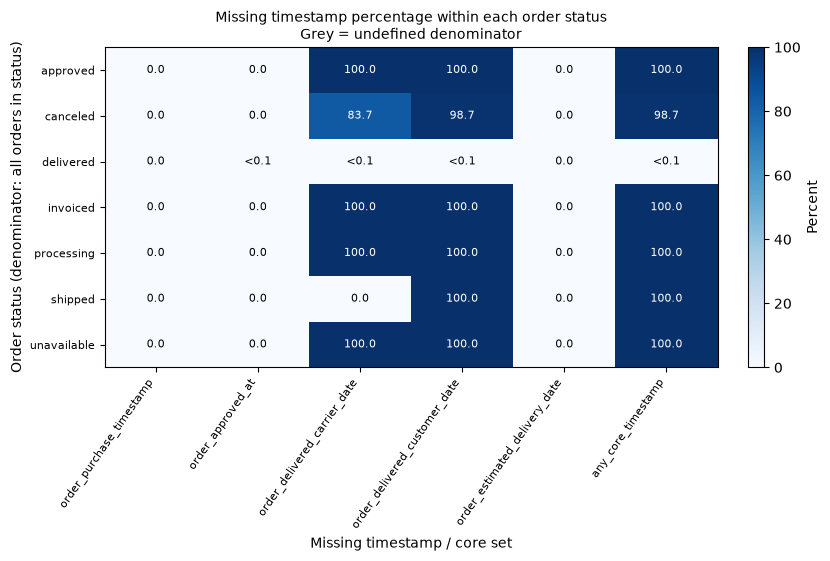

In [31]:
status_missing_rates = inspect_status_missingness(
    condition_profiles=missing_context["condition_profiles"],
    order_timestamp_columns=missing_context["order_timestamp_columns"],
)


## 5. Domain consistency

### Text, identifiers and location codes

Inspect original strings for whitespace, control/replacement characters, type and structural patterns. String IDs are checked against 32 lowercase hexadecimal characters, ZIP prefixes against five ASCII digits and states against two uppercase letters. These are format checks, not address validation.

Regex percentages use evaluated string rows. Temporary stripped/casefolded keys identify candidate spelling variants without modifying or consolidating values. Examples retain original row positions; complete tables remain in `text_format_profiles`.


In [32]:
text_format_profiles = inspect_text_formats(
    column_roles=column_roles,
    missingness_frames=missing_patterns["missingness_frames"],
)


Original text formats | full_items | N=112,650
Value counts and text lengths (checks can overlap)


column,order_id,product_id,seller_id,customer_id,order_status,customer_zip_code_prefix,customer_city,customer_state,product_category_name,seller_zip_code_prefix,seller_city,seller_state
rows,112650,112650,112650,112650,112650,112650,112650,112650,112650,112650,112650,112650
missing,0,0,0,0,0,0,0,0,1603,0,0,0
string_rows,112650,112650,112650,112650,112650,112650,112650,112650,111047,112650,112650,112650
non_string,0,0,0,0,0,0,0,0,0,0,0,0
blank,0,0,0,0,0,0,0,0,0,0,0,0
min_length,32,32,32,32,7,5,3,2,3,5,2,2
max_length,32,32,32,32,11,5,32,2,46,5,40,2


Formatting diagnostics


column,order_id,product_id,seller_id,customer_id,order_status,customer_zip_code_prefix,customer_city,customer_state,product_category_name,seller_zip_code_prefix,seller_city,seller_state
edge_whitespace,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
repeated_whitespace,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,56.0,0.0
control_character,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
replacement_character,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
pattern_evaluated,112650.0,112650.0,112650.0,112650.0,0.0,112650.0,0.0,112650.0,0.0,112650.0,0.0,112650.0
pattern_mismatch,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
pattern_mismatch_pct,0.0,0.0,0.0,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0
candidate_variant_groups,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Regex declarations (no pattern means no regex evaluation)


,column,pattern
0,order_id,[0-9a-f]{32}
1,product_id,[0-9a-f]{32}
2,seller_id,[0-9a-f]{32}
3,customer_id,[0-9a-f]{32}
4,order_status,NaN
5,customer_zip_code_prefix,[0-9]{5}
6,customer_city,NaN
7,customer_state,[A-Z]{2}
8,product_category_name,NaN
9,seller_zip_code_prefix,[0-9]{5}


... (24 outputs left out)

Regex declarations (no pattern means no regex evaluation)


,column,pattern
0,seller_id,[0-9a-f]{32}
1,seller_zip_code_prefix,[0-9]{5}
2,seller_city,NaN
3,seller_state,[A-Z]{2}


Candidate variant forms: showing 0 of 0; full table stays in text_format_profiles
Bounded examples; row_position refers to iloc within the named view


,column,check,row_position,index_label,raw_repr
0,seller_city,repeated_whitespace,532,1302,'sao paulo'
1,seller_city,repeated_whitespace,1472,8625,'sao jose dos pinhais'
2,seller_city,repeated_whitespace,2615,52859,'ferraz de vasconcelos'


### Order timestamp sequence

Evaluate six physical timestamp comparisons and one estimated-date comparison. Comparisons require both timestamps; unavailable comparisons remain NA. Percentages use comparable orders, and flags can overlap.

Physical comparisons retain clock precision. Estimated delivery before purchase uses calendar dates. Equal values are not flagged. Results include original examples and status-specific counts.


In [33]:
order_timeline = inspect_order_timeline(
    entity_views=entity_views,
)


,check,start_column,end_column,comparison_unit,orders,evaluated_orders,unassessable_orders,flagged_orders,flagged_pct_evaluated
0,approved_before_purchase,order_purchase_timestamp,order_approved_at,timestamp,98666,98652,14,0,0.000000
1,carrier_before_approval,order_approved_at,order_delivered_carrier_date,timestamp,98666,97643,1023,1359,1.391805
2,customer_before_carrier,order_delivered_carrier_date,order_delivered_customer_date,timestamp,98666,96475,2191,23,0.023840
3,carrier_before_purchase,order_purchase_timestamp,order_delivered_carrier_date,timestamp,98666,97657,1009,166,0.169983
4,customer_before_approval,order_approved_at,order_delivered_customer_date,timestamp,98666,96462,2204,61,0.063237
5,customer_before_purchase,order_purchase_timestamp,order_delivered_customer_date,timestamp,98666,96476,2190,0,0.000000
6,estimated_before_purchase,order_purchase_timestamp,order_estimated_delivery_date,calendar_date,98666,98666,0,0,0.000000


Orders with any ordering flag: 1,382 of 98,666; flags overlap
Original timestamp examples (at most five per check)


,check,row_position,order_id,order_status,start_column,end_column,comparison_unit,start_value,end_value
0,carrier_before_approval,7,000576fe39319847cbb9d288c5617fa6,delivered,order_approved_at,order_delivered_carrier_date,timestamp,2018-07-05 16:35:48,2018-07-05 12:15:00
1,carrier_before_approval,50,002175704e8b209f61b9ad5cfd92b60e,delivered,order_approved_at,order_delivered_carrier_date,timestamp,2018-04-24 17:24:48,2018-04-23 19:03:19
2,carrier_before_approval,61,002834535f7a609a5c68266f173fa59e,delivered,order_approved_at,order_delivered_carrier_date,timestamp,2018-07-28 23:30:59,2018-07-24 15:53:00
3,carrier_before_approval,106,004345d16a1ab2c21962992c721c8643,delivered,order_approved_at,order_delivered_carrier_date,timestamp,2018-07-05 16:09:18,2018-07-05 14:08:00
4,carrier_before_approval,256,00b4c651133c06fb175123a492f1cac3,delivered,order_approved_at,order_delivered_carrier_date,timestamp,2018-08-17 14:27:21,2018-08-17 13:54:00
5,customer_before_carrier,3575,0922ee1619de7b995648e5a8407afb91,delivered,order_delivered_carrier_date,order_delivered_customer_date,timestamp,2017-07-14 12:41:34,2017-07-12 20:49:42
6,customer_before_carrier,10017,19feb5627c41ea1b36a8e50a469b3644,delivered,order_delivered_carrier_date,order_delivered_customer_date,timestamp,2016-10-26 11:42:05,2016-10-20 19:07:54
7,customer_before_carrier,11093,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,order_delivered_carrier_date,order_delivered_customer_date,timestamp,2017-08-10 18:28:56,2017-08-10 18:05:38
8,customer_before_carrier,15918,29941903985f944b0ffc49c479c1547d,delivered,order_delivered_carrier_date,order_delivered_customer_date,timestamp,2017-06-09 15:07:29,2017-06-02 11:09:16
9,customer_before_carrier,21596,383aa8b2724fe452d9ccd9934a8c628b,delivered,order_delivered_carrier_date,order_delivered_customer_date,timestamp,2017-07-07 17:22:41,2017-07-06 14:27:51


carrier_before_approval by status; unknown_rows means one or both timestamps are absent


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96462,16,1350,1.399515,1.399283
1,shipped,1106,1106,0,9,0.813743,0.813743
2,canceled,461,75,386,0,0.000000,0.000000
3,invoiced,312,0,312,0,NaN,0.000000
4,processing,301,0,301,0,NaN,0.000000
5,approved,2,0,2,0,NaN,0.000000
6,unavailable,6,0,6,0,NaN,0.000000


customer_before_carrier by status; unknown_rows means one or both timestamps are absent


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96469,9,23,0.023842,0.02384
1,shipped,1106,0,1106,0,NaN,0.00000
2,canceled,461,6,455,0,0.000000,0.00000
3,invoiced,312,0,312,0,NaN,0.00000
4,processing,301,0,301,0,NaN,0.00000
5,approved,2,0,2,0,NaN,0.00000
6,unavailable,6,0,6,0,NaN,0.00000


carrier_before_purchase by status; unknown_rows means one or both timestamps are absent


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96476,2,165,0.171027,0.171023
1,shipped,1106,1106,0,1,0.090416,0.090416
2,canceled,461,75,386,0,0.000000,0.000000
3,invoiced,312,0,312,0,NaN,0.000000
4,processing,301,0,301,0,NaN,0.000000
5,approved,2,0,2,0,NaN,0.000000
6,unavailable,6,0,6,0,NaN,0.000000


customer_before_approval by status; unknown_rows means one or both timestamps are absent


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96456,22,61,0.063241,0.063227
1,shipped,1106,0,1106,0,NaN,0.000000
2,canceled,461,6,455,0,0.000000,0.000000
3,invoiced,312,0,312,0,NaN,0.000000
4,processing,301,0,301,0,NaN,0.000000
5,approved,2,0,2,0,NaN,0.000000
6,unavailable,6,0,6,0,NaN,0.000000


### Measurements and item deadlines

Inspect zero, negative, missing and non-finite measurements using the numeric profiles. Zero freight is counted separately.

Compare item deadlines with purchase timestamps where both exist. The nullable condition remains at item grain and does not select an order-level deadline or assign seller delay.


In [34]:
measurement_checks = inspect_measurement_plausibility(
    numeric_profiles=numeric_profiles,
    df=df,
)


,grain,column,rows,finite,missing,non_finite_non_null,zero,negative
0,order_items,price,112650,112650,0,0,0,0
1,order_items,freight_value,112650,112650,0,0,383,0
2,products,product_weight_g,32951,32949,2,0,4,0
3,products,product_length_cm,32951,32949,2,0,0,0
4,products,product_height_cm,32951,32949,2,0,0,0
5,products,product_width_cm,32951,32949,2,0,0,0


Item deadline before purchase by status (evaluated denominator: comparable item rows)


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,110197,110197,0,0,0.0,0.0
1,shipped,1185,1185,0,0,0.0,0.0
2,canceled,542,542,0,0,0.0,0.0
3,invoiced,359,359,0,0,0.0,0.0
4,processing,357,357,0,0,0.0,0.0
5,approved,3,3,0,0,0.0,0.0
6,unavailable,7,7,0,0,0.0,0.0


### Order structure

Count items, products, sellers, distinct deadlines and observed state pairs within each order. Consecutive item numbering requires unique positive integer IDs covering `1..N`.

State equality uses present, non-blank original strings. Missing deadlines and incomparable states are counted separately. Order-seller deadline ranges retain the observed values without selecting a representative deadline.


In [35]:
order_structure = inspect_order_structure(
    df=df,
)


,check,unit,total,affected,affected_pct
0,Multiple items,orders,98666,9803,9.935540
1,Multiple products,orders,98666,3236,3.279752
2,Multiple sellers,orders,98666,1278,1.295279
3,Multiple non-null deadlines,orders,98666,336,0.340543
4,Missing deadline items,orders,98666,0,0.000000
5,Multiple non-null seller states,orders,98666,510,0.516895
6,Both equal and different state pairs,orders,98666,247,0.250340
7,Uncomparable state pairs,orders,98666,0,0.000000
8,Incomplete item numbering,orders,98666,0,0.000000
9,Multiple deadlines within seller,order-seller groups,100010,0,0.000000


item_rows per order | N=98,666


,value,kind,count,total_rows,pct_all
0,1,value,88863,98666,90.064460
1,2,value,7516,98666,7.617619
2,3,value,1322,98666,1.339874
3,4,value,505,98666,0.511828
4,5,value,204,98666,0.206758
5,6,value,198,98666,0.200677
6,7,value,22,98666,0.022297
7,8,value,8,98666,0.008108
8,10,value,8,98666,0.008108
9,12,value,5,98666,0.005068


products per order | N=98,666


,value,kind,count,total_rows,pct_all
0,1,value,95430,98666,96.720248
1,2,value,2846,98666,2.884479
2,3,value,298,98666,0.302029
3,4,value,70,98666,0.070946
4,6,value,10,98666,0.010135
5,5,value,8,98666,0.008108
6,7,value,3,98666,0.003041
7,8,value,1,98666,0.001014
8,<NA>,missing,0,98666,0.000000


sellers per order | N=98,666


... (7 outputs left out)

Mixed equal/different state pairs: 247 orders; at most five examples


,order_id,item_rows,min_item_id,max_item_id,distinct_item_ids,invalid_item_id_rows,sellers,products,deadlines,missing_deadline_items,seller_states_non_null,customer_states_non_null,missing_seller_state_items,missing_customer_state_items,items_with_equal_states,items_with_different_states,items_with_uncomparable_states,consecutive_item_numbers
637,01b1a7fdae9ad1837d6ab861705a1fa5,2,1,2,2,0,2,2,1,0,2,1,0,0,1,1,0,True
1043,02beac5428ccbd30f4b3fbded058289f,2,1,2,2,0,2,2,1,0,2,1,0,0,1,1,0,True
1300,0362e923f805ae4dce58fd78c86c96c4,2,1,2,2,0,2,2,1,0,2,1,0,0,1,1,0,True
2776,071be1c98f3a6f467d8e472d94350db8,2,1,2,2,0,2,2,1,0,2,1,0,0,1,1,0,True
2780,071deb193a4682621c819936d21ae127,2,1,2,2,0,2,2,1,0,2,1,0,0,1,1,0,True


Incomplete item numbering: 0 orders; at most five examples
Order-seller deadline ranges for the first five multi-deadline orders


,order_id,seller_id,item_rows,distinct_deadlines,missing_deadline_items,min_deadline,max_deadline
696,01cce1175ac3c4a450e3a0f856d02734,9c7fd21e0aa159b20da593371f08ff7c,1,1,0,2018-07-25 20:43:14,2018-07-25 20:43:14
697,01cce1175ac3c4a450e3a0f856d02734,0bae85eb84b9fb3bd773911e89288d54,1,1,0,2018-07-23 20:43:14,2018-07-23 20:43:14
961,0282e83acfe3e7aaf60c871a4a9aca61,db4350fd57ae30082dec7acbaacc17f9,1,1,0,2018-05-16 20:57:02,2018-05-16 20:57:02
962,0282e83acfe3e7aaf60c871a4a9aca61,2a6fbeaa7ab9e5d59a35841a8da71ce4,1,1,0,2018-05-17 20:57:02,2018-05-17 20:57:02
1072,02c9fa29186a8d00b3e73d3837ea40e5,08ad4ac1388e4420ca531c3edfc46198,1,1,0,2018-08-22 19:09:45,2018-08-22 19:09:45
1073,02c9fa29186a8d00b3e73d3837ea40e5,6061155addc1e54b4cfb51c1c2a32ad8,1,1,0,2018-08-21 19:09:45,2018-08-21 19:09:45
1112,02e405aa2667a116637cdb4affaf93c0,640e21a7d01df7614a3b4923e990d40c,1,1,0,2018-04-23 23:51:37,2018-04-23 23:51:37
1113,02e405aa2667a116637cdb4affaf93c0,391fc6631aebcf3004804e51b40bcf1e,1,1,0,2018-04-26 23:51:37,2018-04-26 23:51:37
1524,03ecec245220b63fd7f68c1737ba99ba,fe2032dab1a61af8794248c8196565c9,1,1,0,2018-06-13 20:23:08,2018-06-13 20:23:08
1525,03ecec245220b63fd7f68c1737ba99ba,620c87c171fb2a6dd6e8bb4dec959fc6,1,1,0,2018-06-15 20:23:08,2018-06-15 20:23:08


## 6. Detailed record investigations

### Timestamp reversal precision and overlap

Separate observed ordering flags into same-day and earlier-calendar-date reversals. Retain overlapping flag combinations and bounded original examples.

Monthly tables use comparable orders within each purchase month. The two monthly plots show counts among flagged orders; their percentages describe the flagged cohort.


,Check,Comparable orders,Unassessable orders,Flagged orders,Same-day reversal,Earlier-date reversal
0,approved_before_purchase,98652,14,0,0,0
1,carrier_before_approval,97643,1023,1359,679,680
2,customer_before_carrier,96475,2191,23,3,20
3,carrier_before_purchase,97657,1009,166,164,2
4,customer_before_approval,96462,2204,61,23,38
5,customer_before_purchase,96476,2190,0,0,0
6,estimated_before_purchase,98666,0,0,0,0


Unique orders with any observed ordering flag: 1,382 / 98,666
Observed flag combinations within the flagged-order cohort; False means no observed True for that check


,carrier_before_approval,customer_before_carrier,carrier_before_purchase,customer_before_approval,orders
0,True,False,False,False,1132
1,True,False,True,False,166
2,True,False,False,True,61
3,False,True,False,False,23


carrier_before_approval by purchase month; percentages use comparable orders within each month


,purchase_month,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
21,2016-09,3,2,1,0,0.000000,0.000000
20,2016-10,308,277,31,0,0.000000,0.000000
23,2016-12,1,1,0,0,0.000000,0.000000
17,2017-01,789,764,25,0,0.000000,0.000000
4,2017-02,1733,1662,71,1,0.060168,0.057703
14,2017-03,2641,2591,50,0,0.000000,0.000000
1,2017-04,2391,2352,39,24,1.020408,1.003764
5,2017-05,3660,3600,60,14,0.388889,0.382514
18,2017-06,3217,3182,35,4,0.125707,0.124339
19,2017-07,3969,3928,41,21,0.534623,0.529101


Frequency among flagged orders; pct_all denominator=1,359


,value,kind,count,total_rows,pct_all
15,2017-02,value,1,1359,0.073584
6,2017-04,value,24,1359,1.766004
8,2017-05,value,14,1359,1.030169
12,2017-06,value,4,1359,0.294334
7,2017-07,value,21,1359,1.545254
14,2017-08,value,1,1359,0.073584
9,2017-09,value,13,1359,0.956586
16,2017-11,value,1,1359,0.073584
11,2017-12,value,5,1359,0.367918
5,2018-01,value,25,1359,1.839588


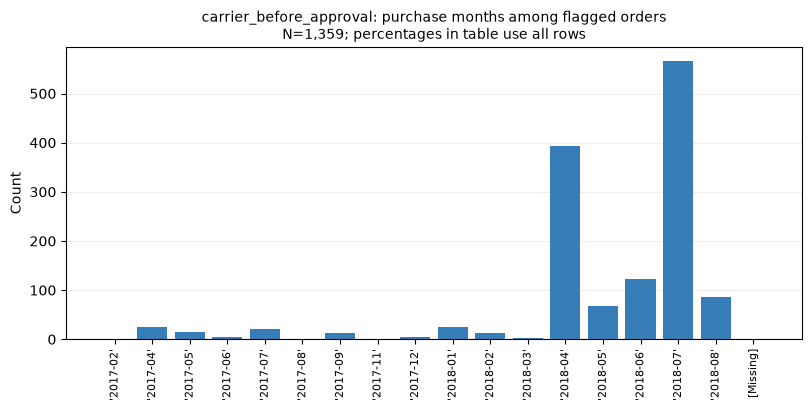

customer_before_carrier by purchase month; percentages use comparable orders within each month


,purchase_month,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
21,2016-09,3,1,2,0,0.000000,0.000000
20,2016-10,308,270,38,4,1.481481,1.298701
23,2016-12,1,1,0,0,0.000000,0.000000
17,2017-01,789,750,39,1,0.133333,0.126743
4,2017-02,1733,1653,80,2,0.120992,0.115407
14,2017-03,2641,2546,95,1,0.039277,0.037864
1,2017-04,2391,2303,88,0,0.000000,0.000000
5,2017-05,3660,3545,115,1,0.028209,0.027322
18,2017-06,3217,3135,82,1,0.031898,0.031085
19,2017-07,3969,3872,97,11,0.284091,0.277148


Frequency among flagged orders; pct_all denominator=23


,value,kind,count,total_rows,pct_all
1,2016-10,value,4,23,17.391304
7,2017-01,value,1,23,4.347826
3,2017-02,value,2,23,8.695652
5,2017-03,value,1,23,4.347826
4,2017-05,value,1,23,4.347826
6,2017-06,value,1,23,4.347826
0,2017-07,value,11,23,47.826087
2,2017-08,value,2,23,8.695652
8,NaN,missing,0,23,0.000000


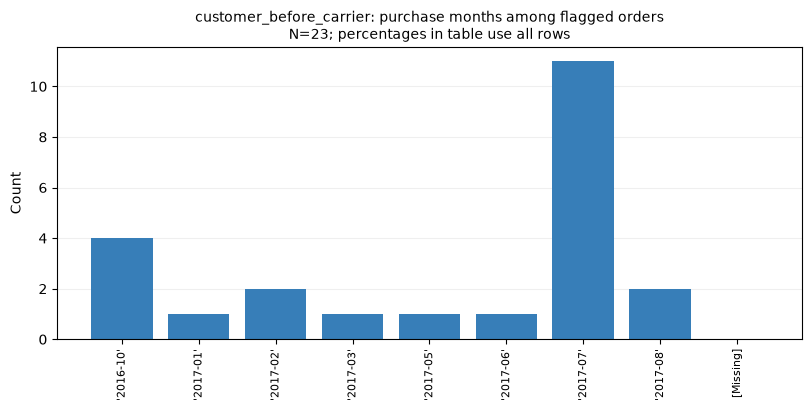

carrier_before_approval | same_calendar_day | at most three original examples


,order_id,order_status,order_approved_at,order_delivered_carrier_date
7,000576fe39319847cbb9d288c5617fa6,delivered,2018-07-05 16:35:48,2018-07-05 12:15:00
118,004345d16a1ab2c21962992c721c8643,delivered,2018-07-05 16:09:18,2018-07-05 14:08:00
283,00b4c651133c06fb175123a492f1cac3,delivered,2018-08-17 14:27:21,2018-08-17 13:54:00


carrier_before_approval | earlier_calendar_date | at most three original examples


,order_id,order_status,order_approved_at,order_delivered_carrier_date
56,002175704e8b209f61b9ad5cfd92b60e,delivered,2018-04-24 17:24:48,2018-04-23 19:03:19
67,002834535f7a609a5c68266f173fa59e,delivered,2018-07-28 23:30:59,2018-07-24 15:53:00
529,0133a47b53fee66218790a8d7dcab993,delivered,2018-04-24 18:59:19,2018-04-23 17:33:54


customer_before_carrier | same_calendar_day | at most three original examples


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
12690,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-10 18:28:56,2017-08-10 18:05:38
27653,3ee6694bb99d5a6db0deceffcd099597,delivered,2017-07-11 18:15:40,2017-07-11 17:41:26
41982,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:42,2017-07-20 18:52:41


... (6 outputs left out)

customer_before_approval | same_calendar_day | at most three original examples


,order_id,order_status,order_approved_at,order_delivered_customer_date
10517,1809078b655469f11b429102fb296998,delivered,2018-04-24 19:10:37,2018-04-24 18:47:46
25628,3a41d0e227b4c6fff055561af5eaca13,delivered,2018-07-05 16:11:06,2018-07-05 14:16:41
34528,4e16f71b2a5ddc0266f9ddfdfd0bcfba,delivered,2018-07-27 23:30:54,2018-07-27 16:46:38


customer_before_approval | earlier_calendar_date | at most three original examples


,order_id,order_status,order_approved_at,order_delivered_customer_date
655,0184d4ddb259e1a4cfc2871888cf97b8,delivered,2017-09-13 22:17:15,2017-09-09 15:12:44
1941,0467205a89711e4ec8e70ef2277e3287,delivered,2018-07-05 16:40:30,2018-07-04 22:42:41
6183,0e1501cd30758f584d1fa67cc6f9493a,delivered,2018-07-05 16:25:45,2018-07-04 23:03:36


In [36]:
timeline_details = inspect_timeline_details(
    entity_views=entity_views,
    timeline_profile=order_timeline["timeline_profile"],
    order_context=missing_context["order_context"],
)


### Core timestamps in delivered orders

Inspect a temporary delivered-order cohort. Retain exact missing-core patterns, original records, purchase-month groups and the overlap with observed ordering flags.

The core set contains purchase, approval, carrier handoff and customer delivery. All statuses remain in the full input.


In [37]:
delivered_completeness = inspect_delivered_completeness(
    orders=entity_views["orders"],
    core_timestamp_columns=missing_context["core_timestamp_columns"],
    any_ordering_flag=timeline_details["any_ordering_flag"],
    order_context=missing_context["order_context"],
)


Delivered orders=96,478; missing any core timestamp=23


,missing_columns,missing_count,rows,total_rows,pct_all,pct_among_missing_orders
1,"(order_approved_at,)",1,14,96478,0.014511,60.869565
2,"(order_delivered_customer_date,)",1,7,96478,0.007256,30.434783
3,"(order_delivered_carrier_date,)",1,1,96478,0.001037,4.347826
4,"(order_delivered_carrier_date, order_delivered_customer_date)",2,1,96478,0.001037,4.347826


Any observed ordering flag,False,True
Any missing core timestamp,,
False,95082,1373
True,23,0


Delivered core-timestamp missingness by purchase month (all delivered orders in each month)


,purchase_month,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
22,2016-09,1,1,0,0,0.000000,0.000000
20,2016-10,265,265,0,0,0.000000,0.000000
21,2016-12,1,1,0,0,0.000000,0.000000
17,2017-01,750,750,0,2,0.266667,0.266667
4,2017-02,1653,1653,0,12,0.725953,0.725953
14,2017-03,2546,2546,0,0,0.000000,0.000000
1,2017-04,2303,2303,0,0,0.000000,0.000000
5,2017-05,3546,3546,0,1,0.028201,0.028201
18,2017-06,3135,3135,0,0,0.000000,0.000000
19,2017-07,3872,3872,0,0,0.000000,0.000000


Missing pattern ('order_approved_at',): at most five original orders


... (3 outputs left out)

Missing pattern ('order_delivered_carrier_date',): at most five original orders


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
18554,2aa91108853cecb43c84a5dc5b277475,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaT,2017-11-20 19:44:47


Missing pattern ('order_delivered_carrier_date', 'order_delivered_customer_date'): at most five original orders


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
19838,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT


### Physical measurements and repeated product exposure

Separate missing physical measurements from nonpositive measurements. Report affected products, their item occurrences and distinct orders with separate denominators.

Compare category/physical co-missingness at product and item grain. Inspect zero freight by status and category without changing values.


In [38]:
product_completeness = inspect_product_completeness(
    entity_views=entity_views,
    product_measurement_columns=missing_context["product_measurement_columns"],
    df=df,
    orders=entity_views["orders"],
)


,Issue,Products,All products,Item rows,All item rows,Orders,All orders
0,any_missing_physical,2,32951,18,112650,16,98666
1,nonpositive_product_weight_g,4,32951,8,112650,6,98666
2,nonpositive_product_length_cm,0,32951,0,112650,0,98666
3,nonpositive_product_height_cm,0,32951,0,112650,0,98666
4,nonpositive_product_width_cm,0,32951,0,112650,0,98666


Unique affected products: 6; original measurements and exposure counts


,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,item_rows,orders,sellers
2972,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0,4,3,1
3052,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0,2,1,1
7098,5eb564652db742ff8f28759cd8d2652a,<NA>,NaN,NaN,NaN,NaN,17,15,1
14080,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0,1,1,1
32984,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0,1,1,1
58833,09ff539a621711667c43eba6a3bd8466,bebes,NaN,NaN,NaN,NaN,1,1,1


,Grain,Missing physical,Also missing category,Category missing pct among missing physical
0,products,2,1,50.000000
1,items,18,17,94.444444


Zero freight: 383 item rows in 339 orders


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,110197,110197,0,381,0.345744,0.345744
1,shipped,1185,1185,0,2,0.168776,0.168776
2,canceled,542,542,0,0,0.000000,0.000000
3,invoiced,359,359,0,0,0.000000,0.000000
4,processing,357,357,0,0,0.000000,0.000000
5,approved,3,3,0,0,0.000000,0.000000
6,unavailable,7,7,0,0,0.000000,0.000000


Top 15 of 74 category groups by zero-freight count; full table retained


,product_category_name,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
26,relogios_presentes,5991,5991,0,214,3.572025,3.572025
2,moveis_decoracao,8334,8334,0,98,1.175906,1.175906
4,ferramentas_jardim,4347,4347,0,56,1.288245,1.288245
10,cama_mesa_banho,11115,11115,0,9,0.080972,0.080972
28,<NA>,1603,1603,0,2,0.124766,0.124766
7,beleza_saude,9670,9670,0,1,0.010341,0.010341
13,moveis_escritorio,1691,1691,0,1,0.059137,0.059137
27,automotivo,4235,4235,0,1,0.023613,0.023613
58,livros_importados,60,60,0,1,1.666667,1.666667
0,cool_stuff,3796,3796,0,0,0.000000,0.000000


### Numeric tails and category composition

Inspect the existing 1.5-IQR tails by product category. Price and freight use item grain; physical measurements use product grain. Retain finite and unassessable denominators.

Complete category tables remain in `numeric_tails`. Displays show up to 15 groups and up to three original records from each numeric extreme.


In [39]:
numeric_tails = inspect_numeric_tails(
    numeric_profiles=numeric_profiles,
    df=df,
    entity_views=entity_views,
)


price | items | top 15 of 74 category groups; full table retained


,product_category_name,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
7,beleza_saude,9670,9670,0,1157,11.964840,11.964840
26,relogios_presentes,5991,5991,0,975,16.274412,16.274412
11,esporte_lazer,8641,8641,0,485,5.612776,5.612776
27,automotivo,4235,4235,0,425,10.035419,10.035419
0,cool_stuff,3796,3796,0,390,10.273973,10.273973
18,informatica_acessorios,7827,7827,0,377,4.816660,4.816660
23,brinquedos,4117,4117,0,354,8.598494,8.598494
3,perfumaria,3419,3419,0,334,9.768938,9.768938
5,utilidades_domesticas,6964,6964,0,312,4.480184,4.480184
4,ferramentas_jardim,4347,4347,0,285,6.556246,6.556246


price: minimum; at most three original records


,order_id,order_item_id,product_id,seller_id,product_category_name,price
27652,3ee6513ae7ea23bdfab5b9ab60bffcb5,1,8a3254bee785a526d548a81a9bc3c9be,96804ea39d96eb908e7c3afdb671bb9e,construcao_ferramentas_construcao,0.85
48625,6e864b3f0ec71031117ad4cf46b7f2a1,1,8a3254bee785a526d548a81a9bc3c9be,96804ea39d96eb908e7c3afdb671bb9e,construcao_ferramentas_construcao,0.85
87081,c5bdd8ef3c0ec420232e668302179113,2,8a3254bee785a526d548a81a9bc3c9be,96804ea39d96eb908e7c3afdb671bb9e,construcao_ferramentas_construcao,0.85


price: maximum; at most three original records


,order_id,order_item_id,product_id,seller_id,product_category_name,price
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,utilidades_domesticas,6735.0
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,pcs,6729.0
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,artes,6499.0


... (27 outputs left out)

,product_id,product_category_name,product_width_cm
164,2f763ba79d9cd987b2034aac7ceffe06,eletronicos,6.0
76096,a69f15dfb803d485e8933e80b9742c1c,relogios_presentes,6.0
14967,7e33f4a1c59f89da30a335b2dc2de187,eletronicos,7.0


product_width_cm: maximum; at most three original records


,product_id,product_category_name,product_width_cm
4431,b17808303e15dd50538c011b44295427,cama_mesa_banho,118.0
2884,3758055ab2434bd36ac78e00b15b5cf6,beleza_saude,105.0
11572,cb428376d66b5e216d2ef9f3b27fc172,instrumentos_musicais,105.0


,Grain,Column,IQR lower,IQR upper,Finite rows,Unassessable rows,Outside IQR,Outside IQR pct of finite
0,items,price,-102.600,277.400,112650,0,8427,7.480692
1,items,freight_value,0.975,33.255,112650,0,12134,10.771416
2,products,product_weight_g,-2100.000,4300.000,32949,2,4551,13.812255
3,products,product_length_cm,-12.000,68.000,32949,2,1380,4.188291
4,products,product_height_cm,-11.500,40.500,32949,2,1892,5.742208
5,products,product_width_cm,-7.500,52.500,32949,2,912,2.767914


### Deadlines beyond the purchase observation years

Compare shipping-deadline years with the latest observed purchase year. Display original item deadlines, lifecycle timestamps and statuses, with separate item, order and order-seller counts.

The observation-year boundary is a descriptive reference; it does not establish an SLA or an invalid-date rule.


In [40]:
deadline_calendar = inspect_deadline_calendar(
    orders=entity_views["orders"],
    df=df,
    order_timestamp_columns=missing_context["order_timestamp_columns"],
)


Observed purchase range: 2016-09-04 21:15:19 to 2018-09-03 09:06:57


,Unit,Count
0,Items,4
1,Orders,3
2,Order-seller groups,3


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,110197,110197,0,2,0.001815,0.001815
1,shipped,1185,1185,0,1,0.084388,0.084388
2,canceled,542,542,0,1,0.184502,0.184502
3,invoiced,359,359,0,0,0.000000,0.000000
4,processing,357,357,0,0,0.000000,0.000000
5,approved,3,3,0,0,0.000000,0.000000
6,unavailable,7,7,0,0,0.000000,0.000000


Showing at most 10 of 4 original item records; full table retained


,order_id,order_item_id,seller_id,order_status,customer_state,seller_state,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,shipping_limit_date
8643,13bdf405f961a6deec817d817f5c6624,1,7a241947449cc45dbfda4f9d0798d9d0,canceled,RJ,MG,2017-03-16 02:30:51,2017-03-16 02:30:51,NaT,NaT,2017-08-08,2020-02-05 03:30:51
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,1,7a241947449cc45dbfda4f9d0798d9d0,shipped,DF,MG,2017-03-14 19:23:22,2017-03-14 19:23:22,2017-03-16 14:31:15,NaT,2017-08-04,2020-02-03 20:23:22
85729,c2bb89b5c1dd978d507284be78a04cb2,1,7a241947449cc45dbfda4f9d0798d9d0,delivered,SP,MG,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,2020-04-09 22:35:08
85730,c2bb89b5c1dd978d507284be78a04cb2,2,7a241947449cc45dbfda4f9d0798d9d0,delivered,SP,MG,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,2020-04-09 22:35:08


### Repeated spaces in seller cities

Inspect affected seller records and their item/order exposure. Compare original city spellings within the same state using temporary collapsed-whitespace/casefolded keys.

`[space]` makes repeated spaces visible in display columns. Original strings remain unchanged; comparison keys do not establish geographic identity.


In [41]:
seller_city_spacing = inspect_seller_city_spacing(
    entity_views=entity_views,
    df=df,
    orders=entity_views["orders"],
)


Repeated-whitespace seller cities: 3 / 3,095 sellers; 56 / 112,650 item rows; 54 / 98,666 orders


,seller_id,seller_zip_code_prefix,seller_city,seller_state,comparison_city,city_with_visible_spaces
1302,ea566164622c6b439516ab18062c42cd,05303,sao paulo,SP,sao paulo,sao[space][space]paulo
8625,8a1ff5c35f6595a73fef4c7b96e4908a,83091,sao jose dos pinhais,PR,sao jose dos pinhais,sao[space][space]jose[space]dos[space]pinhais
52859,e88165a185134e13fdfc85d4fa654db8,08517,ferraz de vasconcelos,SP,ferraz de vasconcelos,ferraz[space]de[space][space]vasconcelos


All original spelling counts for affected comparison keys within the same state


,seller_state,comparison_city,seller_city,sellers,city_with_visible_spaces
0,SP,sao paulo,sao paulo,694,sao[space]paulo
1,SP,sao paulo,sao paulo,1,sao[space][space]paulo
2,PR,sao jose dos pinhais,sao jose dos pinhais,9,sao[space]jose[space]dos[space]pinhais
3,SP,ferraz de vasconcelos,ferraz de vasconcelos,3,ferraz[space]de[space]vasconcelos
4,PR,sao jose dos pinhais,sao jose dos pinhais,1,sao[space][space]jose[space]dos[space]pinhais
5,SP,ferraz de vasconcelos,ferraz de vasconcelos,1,ferraz[space]de[space][space]vasconcelos


### Overlap of seller, deadline and state-pair multiplicity

Retain every observed combination of multiple sellers, multiple deadlines and mixed equal/different state pairs at order grain. Inspect status groups and original item rows for bounded example orders.

These tables describe order composition without assigning a route or choosing a representative seller or deadline.


In [42]:
structure_overlap = inspect_structure_overlap(
    order_composition=order_structure["order_composition"],
    orders=entity_views["orders"],
    df=df,
)


,multiple_sellers,multiple_deadlines,mixed_state_pairs,orders,all_orders,pct_all_orders
0,False,False,False,97388,98666,98.704721
1,True,False,False,758,98666,0.768248
2,True,True,False,273,98666,0.276691
3,True,False,True,184,98666,0.186488
4,True,True,True,63,98666,0.063852


multiple_sellers by status; denominator is all orders in each status


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96478,0,1275,1.321545,1.321545
1,shipped,1106,1106,0,2,0.180832,0.180832
2,canceled,461,461,0,0,0.000000,0.000000
3,invoiced,312,312,0,0,0.000000,0.000000
4,processing,301,301,0,0,0.000000,0.000000
5,approved,2,2,0,0,0.000000,0.000000
6,unavailable,6,6,0,1,16.666667,16.666667


multiple_deadlines by status; denominator is all orders in each status


,order_status,rows,evaluated_rows,unknown_rows,affected_rows,affected_pct_evaluated,affected_pct_all
0,delivered,96478,96478,0,334,0.346193,0.346193
1,shipped,1106,1106,0,1,0.090416,0.090416
2,canceled,461,461,0,0,0.000000,0.000000
3,invoiced,312,312,0,0,0.000000,0.000000
4,processing,301,301,0,0,0.000000,0.000000
5,approved,2,2,0,0,0.000000,0.000000
6,unavailable,6,6,0,1,16.666667,16.666667


mixed_state_pairs by status; denominator is all orders in each status


... (3 outputs left out)

,order_id,order_item_id,seller_id,customer_state,seller_state,shipping_limit_date
788,01cce1175ac3c4a450e3a0f856d02734,1,9c7fd21e0aa159b20da593371f08ff7c,SP,SP,2018-07-25 20:43:14
789,01cce1175ac3c4a450e3a0f856d02734,2,0bae85eb84b9fb3bd773911e89288d54,SP,SP,2018-07-23 20:43:14
1079,0282e83acfe3e7aaf60c871a4a9aca61,1,db4350fd57ae30082dec7acbaacc17f9,RJ,SP,2018-05-16 20:57:02
1080,0282e83acfe3e7aaf60c871a4a9aca61,2,2a6fbeaa7ab9e5d59a35841a8da71ce4,RJ,SC,2018-05-17 20:57:02
1200,02c9fa29186a8d00b3e73d3837ea40e5,1,08ad4ac1388e4420ca531c3edfc46198,RJ,SP,2018-08-22 19:09:45
1201,02c9fa29186a8d00b3e73d3837ea40e5,2,6061155addc1e54b4cfb51c1c2a32ad8,RJ,SP,2018-08-21 19:09:45


mixed_state_pairs: first 3 example orders; showing at most 20 of 6 original item rows


,order_id,order_status,item_rows,sellers,deadlines,items_with_equal_states,items_with_different_states
637,01b1a7fdae9ad1837d6ab861705a1fa5,delivered,2,2,1,1,1
1043,02beac5428ccbd30f4b3fbded058289f,delivered,2,2,1,1,1
1300,0362e923f805ae4dce58fd78c86c96c4,delivered,2,2,1,1,1


,order_id,order_item_id,seller_id,customer_state,seller_state,shipping_limit_date
729,01b1a7fdae9ad1837d6ab861705a1fa5,1,1900267e848ceeba8fa32d80c1a5f5a8,SP,SP,2017-06-02 16:02:58
730,01b1a7fdae9ad1837d6ab861705a1fa5,2,ad273c9eb54ecb4532de4bf75bae9e4e,SP,PR,2017-06-02 16:02:58
1181,02beac5428ccbd30f4b3fbded058289f,1,2009a095de2a2a41626f6c6d7722678d,SP,SP,2017-11-07 04:15:16
1182,02beac5428ccbd30f4b3fbded058289f,2,e9bc59e7b60fc3063eb2290deda4cced,SP,PR,2017-11-07 04:15:16
1474,0362e923f805ae4dce58fd78c86c96c4,1,b92e3c8f9738272ff7c59e111e108d7c,MG,MG,2018-04-19 14:09:47
1475,0362e923f805ae4dce58fd78c86c96c4,2,febab0275244b9a49a623f0bd613ca2f,MG,SP,2018-04-19 14:09:47


## 7. Input preservation

Assert that the full input still matches its initial shape, column order, dtypes, indexed values and row order. The assertion writes no files.


In [43]:
assert df.shape == input_baseline["shape"], "Input shape changed during profiling."
pd.testing.assert_index_equal(df.columns, input_baseline["columns"])
pd.testing.assert_series_equal(df.dtypes, input_baseline["dtypes"])
pd.testing.assert_series_equal(
    pd.util.hash_pandas_object(df, index=True), input_baseline["row_hashes"],
)
print("Input preserved after complete pre-cleaning EDA.")

Input preserved after complete pre-cleaning EDA.
